# SmolLM2-135M comparison, Notebook 1: Base model (no training)

**Nutrition and Food Label Assistant, DS493 Phase 2: comparison run.** Same experiment as the GPT-2 Notebook 1, with `HuggingFaceTB/SmolLM2-135M` instead of GPT-2 Small. It reads `Notebooks/config_smollm2.yaml` and writes only to `smollm2-135m` folders. **No GPT-2 file, checkpoint or result is changed.**


## Step 0. Settings you may change

In [1]:
RUN_MODE = "full"        # "full" = the real run used in the comparison; "smoke" = 5-question trial, saved separately
REQUIRE_GPU = True       # keep True: latency must come from the same T4 as the GPT-2 run

## Step 1. Check the runtime


In [2]:
import os, sys, json, time, hashlib, platform, importlib, importlib.util, subprocess, datetime, random, shutil

if importlib.util.find_spec("google.colab") is not None:
    ENV = "colab"
elif os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or os.path.exists("/kaggle/working"):
    ENV = "kaggle"
else:
    ENV = "local"
print("Environment:", ENV)

def need(pkg, pip_name=None):
    if importlib.util.find_spec(pkg) is None:
        print(f"Installing {pip_name or pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=True)
for p in ["torch", "transformers", "yaml", "pandas", "requests", "safetensors"]:
    need(p, {"yaml": "pyyaml"}.get(p))

import torch, transformers, yaml, pandas as pd, requests
from packaging.version import Version
print("torch", torch.__version__, "| transformers", transformers.__version__, "| python", platform.python_version())
if Version(transformers.__version__) < Version("4.46"):
    raise RuntimeError(f"transformers {transformers.__version__} is too old (need 4.46 or newer). "
                       "Run:  !pip install -U transformers   then Runtime -> Restart session, and run again.")
transformers.logging.set_verbosity_error()      # hide long-text warnings (perplexity reads >1024 tokens in blocks)

if torch.cuda.is_available():
    DEVICE = "cuda"
    GPU = torch.cuda.get_device_name(0)
    print(f"GPU: {GPU}, memory {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    if "T4" not in GPU:
        print(f"NOTE: config expects a Tesla T4, this is {GPU}. Results are valid, but latency is not comparable "
              "with runs on a T4. Use the same GPU for all three notebooks.")
else:
    DEVICE, GPU = "cpu", "none"
    msg = ("No GPU found. In Colab: Runtime -> Change runtime type -> Hardware accelerator: T4 GPU -> Save, then "
           "Runtime -> Run all. In Kaggle: Settings (right panel) -> Accelerator -> GPU T4 x2.")
    if REQUIRE_GPU:
        raise RuntimeError(msg)
    print("WARNING:", msg, "Continuing on CPU because REQUIRE_GPU = False (latency will not be comparable).")

Environment: colab
torch 2.14.1+cu130 | transformers 5.22.1 | python 3.13.16
GPU: Tesla T4, memory 15.6 GB


## Step 2. Download the SmolLM2 config and connect storage (Google Drive)


In [3]:
# ---- Step 2. Download config_smollm2.yaml from GitHub and connect storage ----
import os, re, importlib.util
import requests, yaml

CONFIG_URL = "https://raw.githubusercontent.com/Nutrition-Assistant-System/Nutrition-Assistant/main/Notebooks/config_smollm2.yaml"

# Accept a normal GitHub page link too: github.com/<owner>/<repo>/blob/<branch>/<path> -> Raw link
m = re.match(r"https?://github\.com/([^/]+)/([^/]+)/blob/(.+)", CONFIG_URL.strip())
if m:
    CONFIG_URL = f"https://raw.githubusercontent.com/{m.group(1)}/{m.group(2)}/{m.group(3)}"
    print("Converted the GitHub page link to its Raw link:", CONFIG_URL)

# Environment detection (same rules as Step 1; re-run only if Step 1 was skipped)
if "ENV" not in globals():
    if importlib.util.find_spec("google.colab") is not None:
        ENV = "colab"
    elif os.environ.get("KAGGLE_KERNEL_RUN_TYPE") or os.path.exists("/kaggle/working"):
        ENV = "kaggle"
    else:
        ENV = "local"

# Download config.yaml
try:
    r = requests.get(CONFIG_URL, timeout=30)
except requests.RequestException as e:
    raise RuntimeError(f"Could not reach GitHub to download config.yaml:\n  {e}\n"
                       "Check the internet connection (Kaggle: Settings -> Internet -> On) and run this cell again.")
if r.status_code == 404:
    raise RuntimeError(f"config_smollm2.yaml was not found at\n  {CONFIG_URL}\n"
                       "Upload config_smollm2.yaml to the 'Notebooks' folder of the main branch (names are case-sensitive) "
                       "and that the repository is still public.")
if r.status_code != 200:
    raise RuntimeError(f"Downloading config.yaml failed with HTTP {r.status_code}. Wait a minute and run this cell again.")
if r.text.lstrip()[:15].lower().startswith(("<!doctype", "<html")) or "text/html" in r.headers.get("Content-Type", ""):
    raise RuntimeError(f"The URL returned a web page, not the YAML file:\n  {CONFIG_URL}\n"
                       "Use the Raw link: open the file on GitHub, click 'Raw', and copy that address "
                       "(it starts with https://raw.githubusercontent.com/).")

# Parse it
try:
    cfg = yaml.safe_load(r.text)
except yaml.YAMLError as e:
    raise RuntimeError(f"config.yaml was downloaded but is not valid YAML:\n  {e}\n"
                       "Fix the indicated line in the repository (check indentation and quotes) and run this cell again.")
if not isinstance(cfg, dict) or "paths" not in cfg:
    raise RuntimeError("config.yaml was downloaded but has no 'paths' section. Check that the URL points to the project config.")
missing = [k for k in ("drive_root", "local_fallback_root") if not cfg["paths"].get(k)]
if missing:
    raise RuntimeError(f"config.yaml: paths.{', paths.'.join(missing)} is missing or empty.")
print(f"{CONFIG_URL.rsplit('/', 1)[-1]} loaded from GitHub (config_version {cfg.get('project', {}).get('config_version', '?')})")

# Storage root
if ENV == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = cfg["paths"]["drive_root"]
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive is not mounted. Run this cell again and press 'Allow' in the pop-up.")
elif ENV == "kaggle":
    ROOT = "/kaggle/working/nutrition-assistant"                # download it from the Output tab when finished
else:
    ROOT = os.path.abspath("nutrition-assistant")
os.makedirs(ROOT, exist_ok=True)
print("Environment:", ENV, "| all outputs go under:", ROOT)

config_smollm2.yaml loaded from GitHub (config_version 2)
Mounted at /content/drive
Environment: colab | all outputs go under: /content/drive/MyDrive/nutrition-assistant


## Step 3. Secrets
`HF_TOKEN` is **optional** (SmolLM2-135M is a public model). Add it if you have one: it avoids download rate limits. Tokens are never printed or saved.

In [4]:
def get_secret(name):
    if ENV == "colab":
        try:
            from google.colab import userdata
            return userdata.get(name)
        except Exception:
            pass
    if ENV == "kaggle":
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(name)
        except Exception:
            pass
    return os.environ.get(name)

HF_TOKEN = get_secret("HF_TOKEN")
print("HF_TOKEN:", "found (hidden)" if HF_TOKEN else "not set (fine for SmolLM2-135M)")

HF_TOKEN: not set (fine for SmolLM2-135M)


## Step 4. Shared code and configuration
`prompting_tokens.py` and `scoring.py` are the **same files** used in the GPT-2 run (their fingerprints are saved in the run record). Do not edit them here.

In [5]:
%%writefile prompting_tokens.py
import json, math, os
import torch


def build_prompt(question, cfg):
    """The ONE prompt format used for Base, CPT and SFT, in training and in evaluation."""
    return cfg["prompting"]["template"].format(question=question.strip())


def build_target(answer, cfg):
    """SFT target: a leading space, the answer, then the end marker directly (no space before it,
    which would add an extra "Ġ" token the model must learn to emit before stopping)."""
    return cfg["prompting"]["target"].format(answer=answer.strip())


def _markers(cfg):
    st = cfg["prompting"]["special_tokens"]
    return [st["user"], st["assistant"], st["end"]]


def stop_token_ids(tok, cfg):
    """Generation stops at <|end|> (learned in SFT) or at the tokenizer's EOS (<|endoftext|>)."""
    return sorted({tok.convert_tokens_to_ids(cfg["prompting"]["special_tokens"]["end"]), tok.eos_token_id})


def prepare_project_tokenizer(tok, model, cfg):
    """Base notebook ONLY: add the 3 special tokens, set padding, resize the embeddings, record the IDs."""
    if any(t in tok.get_vocab() for t in _markers(cfg)):
        raise RuntimeError("special tokens already present: load later stages with load_project_checkpoint")
    tok.add_special_tokens({"additional_special_tokens": _markers(cfg)})
    if tok.pad_token is None:                      # GPT-2 has no pad token: pad with EOS (always masked)
        tok.pad_token = tok.eos_token
    model.resize_token_embeddings(len(tok))        # new rows sampled around the mean of existing rows
    return _finish(tok, model, cfg)


def _finish(tok, model, cfg):
    model.generation_config.eos_token_id = stop_token_ids(tok, cfg)
    model.generation_config.pad_token_id = tok.pad_token_id
    return {"special_token_ids": {t: tok.convert_tokens_to_ids(t) for t in _markers(cfg)},
            "vocab_size": len(tok), "base_vocab_size": cfg["prompting"]["project_tokenizer"]["base_vocab_size"],
            "eos_token_id": tok.eos_token_id, "pad_token_id": tok.pad_token_id,
            "stop_token_ids": stop_token_ids(tok, cfg)}


def check_project_tokenizer(tok, model, cfg):
    """Fail loudly if a tokenizer/model pair is not the project tokenizer from config.yaml."""
    exp = cfg["prompting"]["project_tokenizer"]
    problems = []
    for t, i in exp["special_token_ids"].items():
        enc = tok.encode(t, add_special_tokens=False)
        if enc != [i]:
            problems.append(f"{t} encodes to {enc}, expected [{i}]")
    if len(tok) != exp["vocab_size"]:
        problems.append(f"tokenizer size {len(tok)}, expected {exp['vocab_size']}")
    if model.get_input_embeddings().weight.shape[0] != len(tok):
        problems.append(f"embedding rows {model.get_input_embeddings().weight.shape[0]} != tokenizer size {len(tok)}")
    if tok.pad_token_id is None:
        problems.append("no pad token")
    if exp.get("tied_lm_head") and model.lm_head.weight.data_ptr() != model.get_input_embeddings().weight.data_ptr():
        problems.append("input and output embeddings are no longer tied")
    if problems:
        raise RuntimeError("Project tokenizer check failed:\n  - " + "\n  - ".join(problems))
    return True


def load_project_checkpoint(path, cfg, device=None):
    """CPT, SFT and scoring: load a saved checkpoint and its tokenizer; check; never add tokens."""
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(path)
    check_project_tokenizer(tok, model, cfg)
    _finish(tok, model, cfg)
    if device:
        model.to(device)
    return tok, model.eval()


def cpt_collate(blocks):

    ids = torch.tensor([b["input_ids"] for b in blocks])
    return {"input_ids": ids, "attention_mask": torch.ones_like(ids), "labels": ids.clone()}


def sft_collate(batch, pad_id):

    m = max(len(x["input_ids"]) for x in batch)
    pad = lambda x, v: x + [v] * (m - len(x))
    return {"input_ids": torch.tensor([pad(x["input_ids"], pad_id) for x in batch]),
            "attention_mask": torch.tensor([pad([1] * len(x["input_ids"]), 0) for x in batch]),
            "labels": torch.tensor([pad(x["labels"], -100) for x in batch])}


def encode_sft_example(tok, question, answer, cfg, max_length):

    p_ids = tok(build_prompt(question, cfg), add_special_tokens=False)["input_ids"]
    a_ids = tok(build_target(answer, cfg), add_special_tokens=False)["input_ids"]
    if len(p_ids) + len(a_ids) > max_length:
        raise ValueError(f"example longer than max_length={max_length}: the <|end|> marker would be cut off")
    return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}


@torch.no_grad()
def heldout_perplexity(tok, model, text, cfg, block_size=512):

    V = cfg["prompting"]["project_tokenizer"]["base_vocab_size"]
    ids = tok(text, add_special_tokens=False)["input_ids"]
    if any(i >= V for i in ids):
        raise ValueError("held-out text contains project special tokens")
    ids = torch.tensor(ids)
    was_training = model.training
    model.eval()                                   # dropout off: perplexity must be deterministic
    nll, count = 0.0, 0
    for i in range(0, len(ids) - 1, block_size):
        chunk = ids[i:i + block_size].unsqueeze(0).to(model.device)
        if chunk.shape[1] < 2:
            continue
        logits = model(chunk).logits[0, :-1, :V].float()
        nll += torch.nn.functional.cross_entropy(logits, chunk[0, 1:], reduction="sum").item()
        count += chunk.shape[1] - 1
    model.train(was_training)
    return math.exp(nll / count)


def clean_answer(text, cfg):

    for s in cfg["prompting"]["stop_strings"]:
        i = text.find(s)
        if i != -1:
            text = text[:i]
    return text.strip()


@torch.no_grad()
def generate_answer(tok, model, question, cfg):
    g = cfg["generation"]
    stops = stop_token_ids(tok, cfg)
    enc = tok(build_prompt(question, cfg), return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**enc, max_new_tokens=g["max_new_tokens"], do_sample=False, num_beams=1,
                         repetition_penalty=g.get("repetition_penalty", 1.0),
                         eos_token_id=stops, pad_token_id=tok.pad_token_id)
    new = out[0][enc["input_ids"].shape[1]:]
    stopped = bool(len(new)) and int(new[-1]) in stops
    text = tok.decode(new, skip_special_tokens=False)
    return clean_answer(text, cfg), {"new_tokens": int(len(new)), "stopped_at_stop_token": stopped}


def save_with_tokenizer(model, tok, out_dir, cfg):

    os.makedirs(out_dir, exist_ok=True)
    model.save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    json.dump(_finish(tok, model, cfg), open(os.path.join(out_dir, "project_tokens.json"), "w"), indent=2)

Writing prompting_tokens.py


In [6]:
%%writefile scoring.py
import hashlib, json, re
import pandas as pd


def test_fingerprint(df):
    """sha256 of the compact JSON list of [id, question, expected_answer] (config.yaml: test_set.fingerprint)."""
    rows = [[str(r.id), str(r.question), str(r.expected_answer)] for r in df.itertuples()]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()


def normalise(text):
    t = str(text).lower()
    t = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", t)     # thousands separator: 1,139 -> 1139
    return re.sub(r"\s+", " ", t).strip()


def numbers(text):
    return set(re.findall(r"\d+(?:\.\d+)?", normalise(text)))


def declined(answer, cfg):
    pats = cfg["evaluation"]["should_decline"]["patterns"]
    return any(re.search(p, str(answer), re.I) for p in pats)


def auto_score(row, answer, cfg):
    if row["scoring"] == "decline":
        d = declined(answer, cfg)
        return (1.0 if d else 0.0), ("declined" if d else "answered instead of declining"), "auto"
    if row["scoring"] == "key_match":
        if declined(answer, cfg):
            return float(cfg["evaluation"]["short_answers"]["declined_answer_scores"]), "declined a question it should answer", "auto"
        keys = [k.strip() for k in str(row["key_answer"]).split("|") if k.strip()]
        hit = any(numbers(k) and numbers(k) <= numbers(answer) for k in keys)
        return (1.0 if hit else 0.0), ("key value found" if hit else "key value missing"), "auto"
    return None, "pending: needs two hand grades", "human"


def summarise(results):

    auto = results[results.scoring != "manual"]
    dec = results[results.should_decline == "yes"]
    pending = int(results.final_score.isna().sum())
    return {
        "n_questions": int(len(results)),
        "n_pending_manual": pending,
        "accuracy": None if pending else round(100 * results.final_score.astype(float).mean(), 1),
        "accuracy_provisional_auto_only": round(100 * auto.auto_score.astype(float).mean(), 1) if len(auto) else None,
        "n_auto_scored": int(len(auto)),
        "refusal_accuracy": round(100 * dec.auto_score.astype(float).mean(), 1) if len(dec) else None,
        "mean_latency_s": round(float(results.latency_s.mean()), 3),
        "by_difficulty_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                               for k, g in auto.groupby("difficulty")},
        "by_scoring_type_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                                 for k, g in auto.groupby("scoring")},
    }

Writing scoring.py


In [7]:
import importlib, copy, prompting_tokens as pt, scoring as sc
importlib.reload(pt); importlib.reload(sc)
sha = lambda path: hashlib.sha256(open(path, "rb").read()).hexdigest()

# ---- use the config downloaded from GitHub in Step 2 (no second download, no embedded fallback) ----
if "cfg" not in globals() or "r" not in globals() or "CONFIG_URL" not in globals():
    raise RuntimeError("The downloaded config is not available. Run Step 2 first (it downloads config_smollm2.yaml "
                       "from GitHub), then run this cell again. Runtime -> Run all does this in the right order.")
if not str(getattr(r, "url", "")).endswith(".yaml") or r.status_code != 200:
    raise RuntimeError("The Step 2 download is no longer available in memory (the variable 'r' was replaced). "
                       "Run Step 2 again, then this cell.")
try:
    downloaded_cfg = yaml.safe_load(r.text)
except yaml.YAMLError as e:
    raise RuntimeError(f"The config downloaded in Step 2 is not valid YAML:\n  {e}\nFix it in the repository and run Step 2 again.")
if not isinstance(cfg, dict) or cfg != downloaded_cfg:
    raise RuntimeError("The config in memory is not identical to the file downloaded in Step 2 "
                       "(it was changed after the download). Run Step 2 again, then this cell.")
cfg = copy.deepcopy(downloaded_cfg)
CONFIG_SOURCE = f"GitHub: {CONFIG_URL}"
CONFIG_SHA256 = hashlib.sha256(r.content).hexdigest()
print(f"Config: {CONFIG_SOURCE}\n  version {cfg['project']['config_version']} | sha256 {CONFIG_SHA256[:16]}... | identical to the Step 2 download: PASS")

# ---- this notebook must only ever run the SmolLM2 comparison (protects the GPT-2 experiment) ----
MODEL_KEY = cfg["run"]["pipeline_model"]
if cfg["project"].get("experiment") != "smollm2-135m-comparison" or MODEL_KEY != "smollm2-135m":
    raise RuntimeError(f"This notebook is for the SmolLM2-135M comparison, but the config has "
                       f"pipeline_model = {MODEL_KEY!r}. Point CONFIG_URL in Step 2 to Notebooks/config_smollm2.yaml "
                       "(not config.yaml, which belongs to the GPT-2 experiment).")
M = cfg["models"][MODEL_KEY]

# ---- sanity checks on the settings this notebook depends on ----
problems = []
if M["role"] != "pipeline_candidate":
    problems.append(f"run.pipeline_model = {MODEL_KEY} is not a pipeline_candidate")
if cfg["run"]["baseline_references"]:
    problems.append("run.baseline_references is not empty: reference models are not part of this notebook version")
if cfg["generation"]["do_sample"] is not False:
    problems.append("generation.do_sample must be false (greedy decoding, brief)")
if cfg["prompting"]["add_special_tokens_at"] != "project_tokenizer":
    problems.append("prompting.add_special_tokens_at must be project_tokenizer")
if ENV == "colab" and cfg["paths"]["drive_root"] != ROOT:
    problems.append(f"paths.drive_root is {cfg['paths']['drive_root']}, but this notebook uses {ROOT}")
if problems:
    raise RuntimeError("config problem(s):\n - " + "\n - ".join(problems))

SEED = cfg["run"]["seed"]
random.seed(SEED); torch.manual_seed(SEED)
SMOKE = RUN_MODE == "smoke"
STAMP = datetime.datetime.now().strftime("%Y%m%d-%H%M")
RUN_NAME = cfg["run"]["run_name"] or f"{'smoke_' if SMOKE else ''}base_{MODEL_KEY}_{STAMP}"
RESULTS = cfg["paths"]["results_dir"].format(root=ROOT, stage="base", model_key=MODEL_KEY, run_name=RUN_NAME)
CKPT = cfg["paths"]["checkpoints_dir"].format(root=ROOT, model_key=MODEL_KEY) + ("/base_project_smoke" if SMOKE else "/base_project")
EXPORTS = cfg["paths"]["repo_exports_dir"].format(root=ROOT)
COMPARISON = os.path.join(ROOT, "comparison")
for p in [RESULTS, CKPT, EXPORTS]:                    # never write into a GPT-2 folder
    if MODEL_KEY not in p:
        raise RuntimeError(f"Output path {p} is not a {MODEL_KEY} folder; check paths in config_smollm2.yaml.")
for d in [RESULTS, EXPORTS + "/results", COMPARISON + "/rows"]:
    os.makedirs(d, exist_ok=True)
print(f"Model: {MODEL_KEY} ({M['model_id']}) | mode: {RUN_MODE}\nResults:    {RESULTS}\nCheckpoint: {CKPT}")

Config: GitHub: https://raw.githubusercontent.com/Nutrition-Assistant-System/Nutrition-Assistant/main/Notebooks/config_smollm2.yaml
  version 2 | sha256 395eda4b751731e9... | identical to the Step 2 download: PASS
Model: smollm2-135m (HuggingFaceTB/SmolLM2-135M) | mode: full
Results:    /content/drive/MyDrive/nutrition-assistant/results/base/smollm2-135m/base_smollm2-135m_20261113-1325
Checkpoint: /content/drive/MyDrive/nutrition-assistant/checkpoints/smollm2-135m/base_project


## Step 5. Download the data and check the test set
The same files as the GPT-2 run, saved in a separate SmolLM2 cache folder.

In [8]:
DATA = os.path.join(ROOT, f"data_cache_{MODEL_KEY}"); os.makedirs(DATA, exist_ok=True)
GH_TOKEN = get_secret(cfg["credentials"]["secrets"]["github"]) if cfg["data_sources"]["private_repo"] else None

def download(key):
    rel = cfg["data_sources"][key]
    url = f"{cfg['data_sources']['base_url']}/{rel}"
    headers = {"Authorization": f"token {GH_TOKEN}"} if GH_TOKEN else {}
    try:
        r = requests.get(url, headers=headers, timeout=60)
    except requests.RequestException as e:
        raise RuntimeError(f"Could not reach GitHub for {rel}: {e}. Check the internet connection and run this cell again.")
    if r.status_code == 404:
        raise RuntimeError(f"{rel} was not found (404). Check that the file exists at this path in the repository "
                           "(names are case-sensitive: Data/CPT/..., Data/SFT/...). If the repository was made private, "
                           "set data_sources.private_repo: true and add the GITHUB_TOKEN secret.")
    r.raise_for_status()
    path = os.path.join(DATA, os.path.basename(rel))
    open(path, "wb").write(r.content)
    print(f"  {rel}: {len(r.content):,} bytes")
    return path

files = {k: download(k) for k in ["cpt_heldout", "test_questions"]}
heldout_text = open(files["cpt_heldout"], encoding="utf-8").read()
tests = pd.read_csv(files["test_questions"], dtype=str).fillna("")

T = cfg["test_set"]
missing_cols = [c for c in T["columns"] if c not in tests.columns]
if missing_cols:
    raise RuntimeError(f"test_questions.csv is missing columns {missing_cols}")
if len(tests) != T["n_questions"]:
    raise RuntimeError(f"test_questions.csv has {len(tests)} rows, expected {T['n_questions']}")
fp = sc.test_fingerprint(tests)
if fp != T["fingerprint"]["value"]:
    raise RuntimeError("The test set has changed (fingerprint mismatch). Every model must be scored on the same frozen "
                       "test set. If the change was intended, follow test_set.change_policy and update the fingerprint "
                       f"in config.yaml.\n  expected {T['fingerprint']['value']}\n  got      {fp}")
mix = tests.scoring.value_counts().to_dict()
if mix != T["scoring_mix"]:
    raise RuntimeError(f"Scoring mix {mix} differs from config {T['scoring_mix']}")
heldout_docs = [d for d in heldout_text.split("\n\n") if d.strip()]
print(f"Test set OK: {len(tests)} questions, fingerprint matches, mix {mix}")
print(f"Held-out text: {len(heldout_docs)} documents, {len(heldout_text):,} characters")
if SMOKE:
    tests = tests.head(cfg["run"]["smoke_test"]["test_questions"]).copy()
    heldout_text = "\n\n".join(heldout_docs[:max(1, int(len(heldout_docs) * cfg["run"]["smoke_test"]["data_fraction"]))])
    print(f"SMOKE MODE: {len(tests)} questions and {len(heldout_text):,} characters of held-out text")

  Data/CPT/heldout.txt: 56,194 bytes
  Data/test_questions.csv: 8,332 bytes
Test set OK: 30 questions, fingerprint matches, mix {'key_match': 18, 'manual': 8, 'decline': 4}
Held-out text: 99 documents, 56,183 characters


## Step 6. Inspect the SmolLM2 tokenizer, load the model and measure perplexity
*Perplexity* = how surprised the model is by unseen text (lower is better). Token-level perplexity is not comparable between GPT-2 and SmolLM2 (they split text into different tokens), so a **word-level** perplexity is also computed for the comparison.

In [9]:
import math
from transformers import AutoTokenizer, AutoModelForCausalLM
PT = cfg["prompting"]["project_tokenizer"]
BLOCK = cfg["stages"]["cpt"]["block_size"]
t0 = time.time()

# ---- 6a. Inspect the tokenizer BEFORE anything is changed ----
try:
    tok = AutoTokenizer.from_pretrained(M["model_id"], revision=M["revision"], token=HF_TOKEN)
except OSError as e:
    raise RuntimeError(f"Could not download the {M['model_id']} tokenizer from Hugging Face: {e}\n"
                       "Check the internet connection; if you see 'rate limit' or 429, add the HF_TOKEN secret.")
# Llama-type models do not accept token_type_ids; some tokenizer versions return them, and older
# transformers then refuses to generate. Keep only input_ids + attention_mask (saved with the tokenizer).
if "token_type_ids" in tok.model_input_names:
    tok.model_input_names = ["input_ids", "attention_mask"]
    tok.init_kwargs["model_input_names"] = ["input_ids", "attention_mask"]
    print("Tokenizer returned token_type_ids (not used by SmolLM2): removed from its outputs.")
specials = {t: tok.convert_tokens_to_ids(t) for t in tok.all_special_tokens}
print(f"Tokenizer class: {type(tok).__name__} | size: {len(tok):,}")
print(f"BOS {tok.bos_token!r} ({tok.bos_token_id}) | EOS {tok.eos_token!r} ({tok.eos_token_id}) | "
      f"PAD {tok.pad_token!r} ({tok.pad_token_id}) | UNK {tok.unk_token!r} ({tok.unk_token_id})")
print(f"Existing special tokens ({len(specials)}):", specials)
default_ids = tok("Hello world")["input_ids"]
plain_ids = tok("Hello world", add_special_tokens=False)["input_ids"]
print("Adds a BOS/EOS token by default:", default_ids != plain_ids, "(the project always tokenizes with add_special_tokens=False)")
prompt0 = pt.build_prompt(tests.question.iloc[0], cfg)
print("Project prompt BEFORE adding tokens is split into", len(tok(prompt0, add_special_tokens=False)["input_ids"]), "pieces:",
      tok.convert_ids_to_tokens(tok(prompt0, add_special_tokens=False)["input_ids"])[:12], "...")
markers = list(cfg["prompting"]["special_tokens"].values())
data_has_markers = any(m in heldout_text for m in markers) or tests.question.str.contains(r"<\|", regex=True).any()

# ---- 6b. Load the model in float32 (SmolLM2 is stored in bfloat16; the T4 has no bfloat16) ----
from transformers import AutoConfig
_c = AutoConfig.from_pretrained(M["model_id"], revision=M["revision"], token=HF_TOKEN)
stored_dtype = str(getattr(_c, "torch_dtype", None) or getattr(_c, "dtype", None))
dtype_kw = "dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"
try:
    model = AutoModelForCausalLM.from_pretrained(M["model_id"], revision=M["revision"], token=HF_TOKEN,
                                                 **{dtype_kw: getattr(torch, M["dtype"])})
except OSError as e:
    raise RuntimeError(f"Could not download {M['model_id']} from Hugging Face: {e}\n"
                       "Check the internet connection; if you see 'rate limit' or 429, add the HF_TOKEN secret.")
model.to(DEVICE).eval()
MODEL_COMMIT = getattr(model.config, "_commit_hash", None)
emb_rows = model.get_input_embeddings().weight.shape[0]

print(f"Architecture: {type(model).__name__} | embedding rows: {emb_rows:,} | stored as {stored_dtype}, loaded as {model.dtype}")

checks = {
    f"tokenizer size = {PT['base_vocab_size']:,} (config)": len(tok) == PT["base_vocab_size"],
    "embedding rows = tokenizer size (no hidden extra rows)": emb_rows == len(tok),
    "has an EOS token": tok.eos_token_id is not None,
    "tokenizer outputs only input_ids + attention_mask": "token_type_ids" not in tok("a"),
    "EOS is <|endoftext|>": tok.eos_token == "<|endoftext|>",
    "chat tokens not yet in the vocabulary": not any(t in tok.get_vocab() for t in markers),
    "chat tokens do not clash with existing special tokens": not any(t in specials for t in markers),
    "data and test questions never contain '<|'": not data_has_markers,
    "input/output embeddings tied": model.lm_head.weight.data_ptr() == model.get_input_embeddings().weight.data_ptr(),
    "weights loaded in float32": model.dtype == torch.float32,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
if not all(checks.values()):
    raise RuntimeError("The SmolLM2 model/tokenizer is not what config_smollm2.yaml expects (see FAIL lines above). "
                       "Do not continue: send the printed lines for review.")
print(f"Loaded {M['model_id']} (commit {MODEL_COMMIT}) on {DEVICE} in {time.time() - t0:.0f}s, "
      f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")

# ---- 6c. Perplexity (token level, as the brief asks) + word level (comparable with GPT-2) ----
n_words = len(heldout_text.split())
def word_perplexity(tokenizer, token_ppl):
    """Same blocks as pt.heldout_perplexity: total NLL = ln(ppl) x scored tokens, divided by words."""
    n = len(tokenizer(heldout_text, add_special_tokens=False)["input_ids"])
    scored = sum(min(BLOCK, n - i) - 1 for i in range(0, n - 1, BLOCK) if min(BLOCK, n - i) >= 2)
    return math.exp(math.log(token_ppl) * scored / n_words), scored

ppl_plain = pt.heldout_perplexity(tok, model, heldout_text, cfg, block_size=BLOCK)
wppl_plain, n_scored = word_perplexity(tok, ppl_plain)
print(f"Held-out perplexity, plain SmolLM2-135M: {ppl_plain:.3f} per token ({n_scored:,} tokens) | "
      f"{wppl_plain:.2f} per word ({n_words:,} words)")

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Architecture: LlamaForCausalLM | embedding rows: 49,152 | stored as torch.bfloat16, loaded as torch.float32
PASS tokenizer size = 49,152 (config)
PASS embedding rows = tokenizer size (no hidden extra rows)
PASS has an EOS token
PASS tokenizer outputs only input_ids + attention_mask
PASS EOS is <|endoftext|>
PASS chat tokens not yet in the vocabulary
PASS chat tokens do not clash with existing special tokens
PASS data and test questions never contain '<|'
PASS input/output embeddings tied
PASS weights loaded in float32
Loaded HuggingFaceTB/SmolLM2-135M (commit None) on cuda in 16s, 135M parameters
Held-out perplexity, plain SmolLM2-135M: 6.998 per token (20,955 tokens) | 100.00 per word (8,853 words)


## Step 7. Add the three chat tokens (once) and re-check
After this step SmolLM2 has 49,155 tokens. The new tokens are not used by the held-out text, so perplexity must stay the same.

In [10]:
info = pt.prepare_project_tokenizer(tok, model, cfg)
model.to(DEVICE).eval()
pt.check_project_tokenizer(tok, model, cfg)
expected_ids = PT["special_token_ids"]
ids_ok = info["special_token_ids"] == expected_ids and info["vocab_size"] == PT["vocab_size"]
print(("PASS " if ids_ok else "FAIL ") + f"token ids {info['special_token_ids']}, vocabulary {info['vocab_size']}")
if not ids_ok:
    raise RuntimeError(f"Special-token ids differ from config.yaml ({expected_ids}).")

ppl_project = pt.heldout_perplexity(tok, model, heldout_text, cfg, block_size=cfg["stages"]["cpt"]["block_size"])
rel = abs(ppl_project - ppl_plain) / ppl_plain
print(("PASS " if rel < 1e-4 else "FAIL ") + f"perplexity unchanged: {ppl_plain:.3f} -> {ppl_project:.3f} (relative difference {rel:.1e})")
if rel >= 1e-4:
    raise RuntimeError("Perplexity changed after adding the tokens: perplexity must use the original vocabulary only.")

example = pt.build_prompt(tests.question.iloc[0], cfg)
ex_ids = tok(example, add_special_tokens=False)["input_ids"]
print("Prompt used for every model:", repr(example))
print("Its token ids:", ex_ids)
print("Stop token ids:", pt.stop_token_ids(tok, cfg), "| pad token id:", tok.pad_token_id)
wppl_project, _ = word_perplexity(tok, ppl_project)
print(f"Word-level perplexity: {wppl_plain:.2f} -> {wppl_project:.2f}")

# SmolLM2: the markers must not change how the question itself is split
q_ids = tok(" " + tests.question.iloc[0].strip(), add_special_tokens=False)["input_ids"]
inner = ex_ids[1:1 + len(q_ids)]
print(("PASS " if inner == q_ids else "FAIL ") + "question tokens identical inside the prompt and on their own")
if inner != q_ids:
    raise RuntimeError("SmolLM2 splits the question differently next to <|user|>: the prompt format needs review.")

PASS token ids {'<|user|>': 49152, '<|assistant|>': 49153, '<|end|>': 49154}, vocabulary 49155
PASS perplexity unchanged: 6.998 -> 6.998 (relative difference 0.0e+00)
Prompt used for every model: '<|user|> How much protein is in 100 g of whole milk?\n<|assistant|>'
Its token ids: [49152, 1073, 1083, 3677, 314, 281, 216, 33, 32, 32, 310, 282, 2444, 4788, 47, 198, 49153]
Stop token ids: [0, 49154] | pad token id: 0
Word-level perplexity: 100.00 -> 100.00
PASS question tokens identical inside the prompt and on their own


## Step 8. Save the base project checkpoint and prove it reloads identically
The SmolLM2 CPT notebook starts from this folder (separate from the GPT-2 checkpoint). About 550 MB in float32.

In [11]:
if os.path.exists(CKPT):
    print("Replacing the existing checkpoint folder (the base checkpoint is always the same).")
    shutil.rmtree(CKPT)
pt.save_with_tokenizer(model, tok, CKPT, cfg)
tok2, model2 = pt.load_project_checkpoint(CKPT, cfg, device=DEVICE)
same_weights = all(torch.equal(a, b) for a, b in zip(model.state_dict().values(), model2.state_dict().values()))
same_ids = tok2(example, add_special_tokens=False)["input_ids"] == ex_ids
ppl_reload = pt.heldout_perplexity(tok2, model2, heldout_text, cfg, block_size=cfg["stages"]["cpt"]["block_size"])
reload_checks = {"weights identical": same_weights, "prompt token ids identical": same_ids,
                 "perplexity identical": abs(ppl_reload - ppl_project) / ppl_project < 1e-6}
for k, v in reload_checks.items():
    print(("PASS " if v else "FAIL ") + k)
if not all(reload_checks.values()):
    raise RuntimeError(f"The saved checkpoint does not reload identically. Delete {CKPT} and run Step 8 again.")
del model2, tok2
print("Saved:", CKPT, "->", sorted(os.listdir(CKPT)))

Replacing the existing checkpoint folder (the base checkpoint is always the same).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

PASS weights identical
PASS prompt token ids identical
PASS perplexity identical
Saved: /content/drive/MyDrive/nutrition-assistant/checkpoints/smollm2-135m/base_project -> ['config.json', 'generation_config.json', 'model.safetensors', 'project_tokens.json', 'tokenizer.json', 'tokenizer_config.json']


## Step 9. Ask the 30 test questions
Exactly as in the GPT-2 run: greedy decoding, at most 96 new tokens, one question at a time.

In [12]:
torch.manual_seed(SEED)
pt.generate_answer(tok, model, "How much protein is in 100 g of rice?", cfg)     # warm-up, not timed or scored
rows = []
for i, r in enumerate(tests.to_dict("records"), 1):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    answer, meta = pt.generate_answer(tok, model, r["question"], cfg)
    if DEVICE == "cuda": torch.cuda.synchronize()
    secs = time.perf_counter() - t0
    rows.append({**r, "model_answer": answer, "new_tokens": meta["new_tokens"],
                 "stopped_at_stop_token": meta["stopped_at_stop_token"], "latency_s": round(secs, 4)})
    print(f"[{i:2d}/{len(tests)}] {secs:5.2f}s  Q{r['id']}: {answer[:90]!r}")

[ 1/30]  2.92s  Q1: 'How much protein is in 100 g of whole milk?\n\nHow much protein is in 100 g of whole milk?\n\n'
[ 2/30]  3.36s  Q2: 'How many calories are in 100 g of banana?\n\n## How many calories are in 100 g of banana?\n\nH'
[ 3/30]  3.27s  Q3: 'How much fibre is in 100 g of cooked lentils?\n\nHow much fibre is in 100 g of cooked lentil'
[ 4/30]  2.94s  Q4: 'How much fat is in 100 g of raw almonds?\n\nHow much fat is in 100 g of raw almonds?\n\nHow mu'
[ 5/30]  2.84s  Q5: 'How much sodium is in 100 g of feta cheese?\n\nHow much sodium is in 100 g of feta cheese?\n\n'
[ 6/30]  3.12s  Q6: "What are the nutritional values of Kellogg's Special K The Original cereal?\n\nThe nutrition"
[ 7/30]  4.84s  Q7: 'How many calories are in 100 g of hard-boiled egg?\n\nHow many calories are in 100 g of hard'
[ 8/30]  3.98s  Q8: 'How much sugar is in 100 g of Medjool dates?\n\nHow much sugar is in 100 g of Medjool dates?'
[ 9/30]  2.94s  Q9: 'How much calcium is in 100 g of plain whole-milk yo

## Step 10. Score the answers

In [13]:
res = pd.DataFrame(rows)
scored = [sc.auto_score(r, r["model_answer"], cfg) for r in res.to_dict("records")]
res["auto_score"] = [s for s, _, _ in scored]
res["auto_reason"] = [w for _, w, _ in scored]
res["score_source"] = [src for _, _, src in scored]
for c in ["grader_1", "grader_2"]:
    res[c] = None
res["final_score"] = res["auto_score"]                     # manual rows stay empty (pending)
metrics = sc.summarise(res)
metrics.update({"heldout_perplexity": round(ppl_project, 3), "heldout_perplexity_before_tokens": round(ppl_plain, 3),
                "perplexity_vocab": f"original {PT['base_vocab_size']:,} tokens", "heldout_word_perplexity": round(wppl_project, 3),
                "heldout_scored_tokens": n_scored, "heldout_words": n_words, "answers_stopped_at_stop_token":
                int(res.stopped_at_stop_token.sum()), "mean_new_tokens": round(float(res.new_tokens.mean()), 1)})
print(json.dumps(metrics, indent=2))
display(res[["id", "scoring", "auto_score", "auto_reason", "model_answer"]])

{
  "n_questions": 30,
  "n_pending_manual": 8,
  "accuracy": null,
  "accuracy_provisional_auto_only": 0.0,
  "n_auto_scored": 22,
  "refusal_accuracy": 0.0,
  "mean_latency_s": 3.187,
  "by_difficulty_auto": {
    "easy": 0.0,
    "medium": 0.0,
    "refusal": 0.0
  },
  "by_scoring_type_auto": {
    "decline": 0.0,
    "key_match": 0.0
  },
  "heldout_perplexity": 6.998,
  "heldout_perplexity_before_tokens": 6.998,
  "perplexity_vocab": "original 49,152 tokens",
  "heldout_word_perplexity": 100.005,
  "heldout_scored_tokens": 20955,
  "heldout_words": 8853,
  "answers_stopped_at_stop_token": 0,
  "mean_new_tokens": 96.0
}


,id,scoring,auto_score,auto_reason,model_answer
0,1,key_match,0.0,key value missing,How much protein is in 100 g of whole milk?\n\...
1,2,key_match,0.0,key value missing,How many calories are in 100 g of banana?\n\n#...
2,3,key_match,0.0,key value missing,How much fibre is in 100 g of cooked lentils?\...
3,4,key_match,0.0,key value missing,How much fat is in 100 g of raw almonds?\n\nHo...
4,5,key_match,0.0,key value missing,How much sodium is in 100 g of feta cheese?\n\...
5,6,manual,NaN,pending: needs two hand grades,What are the nutritional values of Kellogg's S...
6,7,key_match,0.0,key value missing,How many calories are in 100 g of hard-boiled ...
7,8,key_match,0.0,key value missing,How much sugar is in 100 g of Medjool dates?\n...
8,9,key_match,0.0,key value missing,How much calcium is in 100 g of plain whole-mi...
9,10,key_match,0.0,key value missing,How much iron is in 100 g of raw spinach?\n\nH...


## Step 11. Save results and update the comparison scoreboard
SmolLM2 results go to `smollm2-135m` folders only. The comparison scoreboard reads the GPT-2 results without changing them.

In [14]:
cols = ["id", "question", "expected_answer", "key_answer", "difficulty", "scoring", "should_decline", "model_answer",
        "new_tokens", "stopped_at_stop_token", "latency_s", "auto_score", "auto_reason", "score_source",
        "grader_1", "grader_2", "final_score"]
res[cols].to_csv(f"{RESULTS}/answers.csv", index=False)
manual = res[res.scoring == "manual"][["id", "question", "expected_answer", "model_answer", "grader_1", "grader_2", "final_score"]].copy()
manual["notes"] = ""
manual.to_csv(f"{RESULTS}/manual_grading_sheet.csv", index=False)
json.dump(metrics, open(f"{RESULTS}/metrics.json", "w"), indent=2)
yaml.safe_dump(cfg, open(f"{RESULTS}/config_used.yaml", "w"), sort_keys=False, allow_unicode=True)

manifest = {
    "notebook": "01_base_model_smollm2", "run_name": RUN_NAME, "mode": RUN_MODE, "finished": datetime.datetime.now().isoformat(),
    "model_key": MODEL_KEY, "model_id": M["model_id"], "model_commit": MODEL_COMMIT, "checkpoint": CKPT,
    "config_source": CONFIG_SOURCE, "config_sha256": CONFIG_SHA256, "config_version": cfg["project"]["config_version"],
    "sha256": {"prompting_tokens.py": sha("prompting_tokens.py"), "scoring.py": sha("scoring.py"),
               "heldout.txt": sha(files["cpt_heldout"]), "test_questions.csv": sha(files["test_questions"])},
    "test_fingerprint": fp, "project_tokens": info, "seed": SEED,
    "tokenizer_inspection": {"class": type(tok).__name__, "existing_special_tokens": specials,
                             "adds_special_tokens_by_default": default_ids != plain_ids, "stored_dtype": stored_dtype},
    "environment": {"env": ENV, "gpu": GPU, "torch": torch.__version__, "transformers": transformers.__version__,
                    "python": platform.python_version()},
}
json.dump(manifest, open(f"{RESULTS}/run_manifest.json", "w"), indent=2)
if not SMOKE:
    res[cols].to_csv(f"{EXPORTS}/results/results_base.csv", index=False)
    json.dump({"model": MODEL_KEY, "stage": "base", **metrics, "run_name": RUN_NAME},
              open(f"{EXPORTS}/results/metrics_base.json", "w"), indent=2)
print("Saved to", RESULTS, "->", sorted(os.listdir(RESULTS)))

# ---------------- comparison scoreboard (GPT-2 results are only READ, never changed) ----------------
import glob
ROWS = os.path.join(COMPARISON, "rows")
def row_from(model_key, stage, m, run_name, word_ppl, note=""):
    return {"model": model_key, "stage": stage, "run_name": run_name,
            "heldout_perplexity": m.get("heldout_perplexity"), "word_perplexity": None if word_ppl is None else round(word_ppl, 2),
            "accuracy": m.get("accuracy"), "accuracy_provisional": m.get("accuracy_provisional_auto_only"),
            "refusal_accuracy": m.get("refusal_accuracy"), "mean_latency_s": m.get("mean_latency_s"),
            "n_pending_manual": m.get("n_pending_manual"), "note": note}

if not SMOKE:
    json.dump(row_from(MODEL_KEY, "base", metrics, RUN_NAME, wppl_project), open(f"{ROWS}/{MODEL_KEY}_base.json", "w"), indent=2)

    # GPT-2 base row, built read-only from the latest full GPT-2 Notebook 1 run (if it is on this Drive)
    g_runs = sorted(glob.glob(f"{ROOT}/results/base/gpt2-small/base_gpt2-small_*/metrics.json"))
    g_tok_dir = f"{ROOT}/checkpoints/gpt2-small/base_project"
    if g_runs and os.path.isdir(g_tok_dir):
        g_m = json.load(open(g_runs[-1]))
        g_tok = AutoTokenizer.from_pretrained(g_tok_dir)                     # tokenizer only, read-only
        g_wppl, _ = word_perplexity(g_tok, g_m["heldout_perplexity"])
        json.dump(row_from("gpt2-small", "base", g_m, os.path.basename(os.path.dirname(g_runs[-1])), g_wppl,
                           "from the GPT-2 Notebook 1 run (read-only)"), open(f"{ROWS}/gpt2-small_base.json", "w"), indent=2)
    else:
        print("NOTE: GPT-2 base results not found on this Drive; the GPT-2 rows stay 'pending'.")

    fmt = lambda v, suf="": "pending" if v is None else f"{v}{suf}"
    names = {"gpt2-small": "GPT-2 Small (124M)", "smollm2-135m": "SmolLM2-135M"}
    stages = [("base", "Base"), ("cpt", "+ continued pretraining"), ("sft", "+ SFT")]
    lines = ["# Comparison scoreboard: GPT-2 Small vs SmolLM2-135M", "",
             "Same data, splits, test questions (fingerprint " + cfg["test_set"]["fingerprint"]["value"][:12] + "...), prompt, "
             "greedy decoding (96 new tokens), scoring rules and T4 GPU for both models.", "",
             "| " + " | ".join(cfg["comparison"]["columns"]) + " |", "|" + "---|" * len(cfg["comparison"]["columns"])]
    for mk in cfg["comparison"]["models"]:
        for sk, label in stages:
            p = f"{ROWS}/{mk}_{sk}.json"
            if os.path.exists(p):
                rr = json.load(open(p))
                acc = fmt(rr["accuracy"], "%") if rr["accuracy"] is not None else f"pending ({rr['n_pending_manual']} hand grades)"
                cells_ = [names.get(mk, mk), label, fmt(rr["heldout_perplexity"]), fmt(rr["word_perplexity"]), acc,
                          fmt(rr["accuracy_provisional"], "%"), fmt(rr["refusal_accuracy"], "%"), fmt(rr["mean_latency_s"]), rr["note"]]
            else:
                cells_ = [names.get(mk, mk), label] + ["pending"] * (len(cfg["comparison"]["columns"]) - 3) + ["not run yet"]
            lines.append("| " + " | ".join(str(c) for c in cells_) + " |")
    lines += ["", "Notes:",
              "- Held-out perplexity (own tokens): what the brief asks for; compare it only within one model (before/after training), "
              "because GPT-2 and SmolLM2 split text into different tokens.",
              "- Word-level perplexity = exp(total loss / number of words in the held-out text): the same text and the same "
              "word count for both models, so this column can be compared across models.",
              "- Accuracy stays pending until two graders finish the 8 hand-graded questions (never counted as 0)."]
    open(f"{COMPARISON}/COMPARISON_SCOREBOARD.md", "w").write("\n".join(lines) + "\n")
    print("\n".join(lines))

Saved to /content/drive/MyDrive/nutrition-assistant/results/base/smollm2-135m/base_smollm2-135m_20261113-1325 -> ['answers.csv', 'config_used.yaml', 'manual_grading_sheet.csv', 'metrics.json', 'run_manifest.json']
# Comparison scoreboard: GPT-2 Small vs SmolLM2-135M

Same data, splits, test questions (fingerprint 0ab302fef36a...), prompt, greedy decoding (96 new tokens), scoring rules and T4 GPU for both models.

| Model | Stage | Held-out perplexity (own tokens) | Word-level perplexity | Accuracy | Provisional accuracy (22 auto) | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|---|---|---|
| GPT-2 Small (124M) | Base | 12.294 | 139.34 | pending (8 hand grades) | 0.0% | 0.0% | 1.069 | from the GPT-2 Notebook 1 run (read-only) |
| GPT-2 Small (124M) | + continued pretraining | pending | pending | pending | pending | pending | pending | not run yet |
| GPT-2 Small (124M) | + SFT | pending | pending | pending | pending | pending | pending | not run yet |
| SmolLM2-

## Step 12. Final check

In [15]:
ids_label = "-".join(str(i) for i in (min(PT["special_token_ids"].values()), max(PT["special_token_ids"].values())))
final = {
    "test set unchanged (fingerprint)": fp == cfg["test_set"]["fingerprint"]["value"],
    f"3 chat tokens added once with ids {ids_label}": info["special_token_ids"] == PT["special_token_ids"],
    "perplexity unchanged by the new tokens": rel < 1e-4,
    "checkpoint reloads identically": all(reload_checks.values()),
    f"all {len(tests)} questions answered": len(res) == len(tests),
    "manual questions pending (not counted as 0)": res[res.scoring == "manual"].final_score.isna().all(),
    "results saved": all(os.path.exists(f"{RESULTS}/{f}") for f in ["answers.csv", "metrics.json", "run_manifest.json"]),
    "all outputs in smollm2-135m folders": all(MODEL_KEY in p for p in [RESULTS, CKPT, EXPORTS]),
}
for k, v in final.items():
    print(("PASS " if v else "FAIL ") + k)
if not all(final.values()):
    raise RuntimeError("Some final checks failed (see FAIL lines).")
print(f"""
SMOLLM2 NOTEBOOK 1 FINISHED SUCCESSFULLY ({RUN_MODE} mode)
  Held-out perplexity:          {metrics['heldout_perplexity']} per token | {metrics['heldout_word_perplexity']} per word
  Provisional accuracy (auto):  {metrics['accuracy_provisional_auto_only']}%  over {metrics['n_auto_scored']} auto-scored questions
  Refusal accuracy:             {metrics['refusal_accuracy']}%
  Avg. latency:                 {metrics['mean_latency_s']} s
  Pending hand grades:          {metrics['n_pending_manual']} (final accuracy after both graders finish)
  Checkpoint for SmolLM2 CPT:   {CKPT}
  Results:                      {RESULTS}
  Comparison scoreboard:        {COMPARISON}/COMPARISON_SCOREBOARD.md""")

PASS test set unchanged (fingerprint)
PASS 3 chat tokens added once with ids 49152-49154
PASS perplexity unchanged by the new tokens
PASS checkpoint reloads identically
PASS all 30 questions answered
PASS manual questions pending (not counted as 0)
PASS results saved
PASS all outputs in smollm2-135m folders

SMOLLM2 NOTEBOOK 1 FINISHED SUCCESSFULLY (full mode)
  Held-out perplexity:          6.998 per token | 100.005 per word
  Provisional accuracy (auto):  0.0%  over 22 auto-scored questions
  Refusal accuracy:             0.0%
  Avg. latency:                 3.187 s
  Pending hand grades:          8 (final accuracy after both graders finish)
  Checkpoint for SmolLM2 CPT:   /content/drive/MyDrive/nutrition-assistant/checkpoints/smollm2-135m/base_project
  Results:                      /content/drive/MyDrive/nutrition-assistant/results/base/smollm2-135m/base_smollm2-135m_20261113-1325
  Comparison scoreboard:        /content/drive/MyDrive/nutrition-assistant/comparison/COMPARISON_SCORE

## Step 13. Visual summary: SmolLM2-135M base
The same three figures as the GPT-2 Notebook 1, drawn only from the files saved in Step 11. Hand-graded questions are shown as *pending*, never as 0. Colours are the stage colours of `02_cpt_model.ipynb` (Base `#A4193E`, CPT `#5C8CE6`, SFT `#D35697`).

In [16]:
%%writefile plots.py
"""Report figures shared by Notebooks 1-3 (Base, CPT, SFT): one style, one colour per model, one question order.

Figures are drawn ONLY from the files each notebook saved (answers.csv, metrics.json, manual_grading_sheet.csv),
so they show exactly what was scored. Hand-graded questions stay 'pending' until both graders and a final score
are filled in; they are never drawn as wrong.
"""
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch

# ---- colours: the model colours of 02_cpt_model.ipynb (BASE_C, CPT_C, VAL_C), checked for colour-blind separation ----
MODEL_COLORS = {"Base": "#A4193E", "CPT": "#5C8CE6", "SFT": "#D35697"}
INK, INK2, MUTED = "#19131B", "#52514e", "#898781"          # INK = GREY of 02_cpt_model.ipynb
GRID, AXIS, SURFACE, LIMIT = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#c3c2b7"
ORDER = ["key_match", "decline", "manual"]
GROUP_LABEL = {"key_match": "Key value (auto)", "decline": "Decline (auto)", "manual": "Hand-graded"}


def style():
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": SURFACE,
        "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.dpi": 110})


def load_run(results_dir):
    """answers.csv + metrics.json of one run; final hand grades from manual_grading_sheet.csv are merged in."""
    a = pd.read_csv(f"{results_dir}/answers.csv", dtype={"id": str})
    m = json.load(open(f"{results_dir}/metrics.json"))
    sheet = f"{results_dir}/manual_grading_sheet.csv"
    if os.path.exists(sheet):
        g = pd.read_csv(sheet, dtype={"id": str})
        done = g.dropna(subset=["grader_1", "grader_2", "final_score"]).set_index("id")["final_score"].astype(float)
        a.loc[a.id.isin(done.index), "final_score"] = a.loc[a.id.isin(done.index), "id"].map(done)
    a["g"] = pd.Categorical(a.scoring, ORDER, ordered=True)
    a["idn"] = a.id.astype(int)
    return a.sort_values(["g", "idn"]).reset_index(drop=True), m


def _title(fig, text, y=1.0):
    fig.suptitle(text, x=0.01, y=y, ha="left", fontsize=12, fontweight="bold", color=INK)


def _count(a, scoring):
    d = a[a.scoring == scoring]
    graded = d.final_score.notna()
    return float(d.final_score[graded].sum()), int(graded.sum()), int((~graded).sum())   # half credit counts 0.5


def composition_table(a):
    """Test set: question type x difficulty (a table, not a chart)."""
    t = pd.crosstab(a.scoring.map(GROUP_LABEL), a.difficulty, margins=True, margins_name="total")
    return t.reindex([GROUP_LABEL[g] for g in ORDER] + ["total"])


def fig_headline(a, m, label, path, number):
    """Six stat tiles; counts always shown with their denominators; pending never shown as 0."""
    k_ok, k_n, _ = _count(a, "key_match")
    d_ok, d_n, _ = _count(a, "decline")
    h_ok, h_n, h_p = _count(a, "manual")
    stopped = int(a.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
    tiles = [("Held-out perplexity", f"{m['heldout_perplexity']:.2f}", "per token, 99 held-out documents"),
             ("Key-value questions", f"{k_ok:g} / {k_n}", "correct (automatic)"),
             ("Should-decline questions", f"{d_ok:g} / {d_n}", "declined correctly (automatic)"),
             ("Hand-graded questions", f"{h_p} pending" if h_p else f"{h_ok:g} / {h_n}",
              "not counted until both graders finish" if h_p else "final score of the two graders"),
             ("Stopped at <|end|>", f"{stopped} / {len(a)}", f"the rest ran to the {int(a.new_tokens.max())}-token limit"),
             ("Mean latency", f"{m['mean_latency_s']:.2f} s", "per answer, T4 GPU, greedy")]
    fig = plt.figure(figsize=(10.5, 2.9))
    _title(fig, f"Figure {number}. {label}: headline results")
    for k, (t, v, s) in enumerate(tiles):
        ax = fig.add_axes([0.01 + (k % 3) * 0.33, 0.47 - (k // 3) * 0.45, 0.31, 0.38]); ax.axis("off")
        ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.06", fc=SURFACE, ec=GRID, lw=1,
                                    transform=ax.transAxes))
        ax.text(0.05, 0.78, t, color=INK2, fontsize=9, transform=ax.transAxes)
        ax.text(0.05, 0.40, v, color=INK, fontsize=17, fontweight="bold", transform=ax.transAxes)
        ax.text(0.05, 0.12, s, color=MUTED, fontsize=8, transform=ax.transAxes)
    fig.savefig(path); return fig


def fig_outcomes(runs, path, number):
    """One row per model (Base / CPT / SFT), one cell per test question, grouped by question type.
    Filled cell with a tick = correct; pale cell with a cross = wrong; grey hatched = pending hand grade."""
    names = [n for n, _ in runs]
    fig, ax = plt.subplots(figsize=(10.5, 1.05 + 0.55 * len(runs)))
    ax.grid(False)
    ref = runs[0][1]
    for r, (name, a) in enumerate(runs):
        assert list(a.id) == list(ref.id), "all models must be scored on the same questions"
        y, col = len(runs) - 1 - r, MODEL_COLORS[name]
        for x, row in enumerate(a.itertuples()):
            if pd.isna(row.final_score):
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=GRID, ec="white", lw=0, hatch="////"))
            elif row.final_score >= 1:
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=col, lw=0))
                ax.text(x + .5, y + .5, "✓", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
            else:
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=col, alpha=.16, lw=0))
                ax.text(x + .5, y + .5, "✕" if row.final_score == 0 else "½", ha="center", va="center", color=INK, fontsize=8)
    edges = np.cumsum([0] + [int((ref.scoring == g).sum()) for g in ORDER])
    for g, lo, hi in zip(ORDER, edges[:-1], edges[1:]):
        ax.text((lo + hi) / 2, len(runs) + .15, f"{GROUP_LABEL[g]}\nn={hi - lo}", ha="center", va="bottom", color=INK2, fontsize=8.5)
        if lo:
            ax.axvline(lo, color=INK2, lw=1.2)
    ax.set_xlim(0, len(ref)); ax.set_ylim(0, len(runs) + 1.0)
    ax.set_yticks([len(runs) - 1 - r + .5 for r in range(len(runs))]); ax.set_yticklabels(names, color=INK)
    ax.set_xticks(np.arange(len(ref)) + .5); ax.set_xticklabels(ref.id, fontsize=7.5); ax.set_xlabel("test question id")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    c0 = MODEL_COLORS[names[0]]
    ax.legend(handles=[Patch(fc=c0, label="✓ correct"), Patch(fc=c0, alpha=.16, label="✕ wrong  (½ = half credit)"),
                       Patch(fc=GRID, hatch="////", label="pending hand grade (not counted)")],
              loc="upper center", bbox_to_anchor=(.5, -.42 - .04 * len(runs)), ncol=3, fontsize=8.5)
    _title(fig, f"Figure {number}. Outcome of each of the {len(ref)} test questions", y=1.02)
    fig.savefig(path); return fig


def fig_behaviour(runs, path, number):
    """(a) how answers ended (stopped at <|end|> vs hit the token limit), per question type and model;
    (b) latency per answer."""
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2 + 0.25 * (len(runs) - 1)), gridspec_kw={"width_ratios": [1, 1.25]})
    h = 0.62 / len(runs)
    for k, (name, a) in enumerate(runs):
        col = MODEL_COLORS[name]
        for i, g in enumerate(ORDER):
            d = a[a.scoring == g]
            st = int(d.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
            y = (len(ORDER) - 1 - i) + (len(runs) - 1) / 2 * h - k * h
            ax[0].barh(y, st, height=h * .9, color=col, zorder=3)
            ax[0].barh(y, len(d) - st, left=st, height=h * .9, color=LIMIT, zorder=3)
            ax[0].text(len(d) + .3, y, f"{name}: {st} stopped / {len(d) - st} at limit" if len(runs) > 1
                       else f"{st} stopped / {len(d) - st} at limit", va="center", color=INK, fontsize=8.5)
    ax[0].set_yticks(range(len(ORDER))[::-1]); ax[0].set_yticklabels([GROUP_LABEL[g] for g in ORDER], color=INK)
    ax[0].set_xlim(0, 30); ax[0].set_xlabel("number of answers"); ax[0].grid(axis="y", visible=False)
    ax[0].legend(handles=[Patch(fc=MODEL_COLORS[n], label=f"{n}: stopped at <|end|>") for n, _ in runs]
                 + [Patch(fc=LIMIT, label=f"hit the {int(runs[0][1].new_tokens.max())}-token limit")],
                 loc="upper center", bbox_to_anchor=(.5, -.25), ncol=len(runs) + 1 if len(runs) < 3 else 2, fontsize=8.5)
    ax[0].set_title("(a) How answers ended")
    if len(runs) == 1:
        name, a = runs[0]; d = a.sort_values("idn")
        ax[1].bar(d.idn, d.latency_s, width=.62, color=MODEL_COLORS[name], zorder=3)
        mu = d.latency_s.mean(); ax[1].axhline(mu, color=INK, lw=1.2, zorder=4)
        ax[1].text(d.idn.max() + .4, mu + .03 * d.latency_s.max(), f"mean {mu:.2f} s", va="bottom", ha="right", color=INK, fontsize=8.5)
        ax[1].set_xlim(.3, d.idn.max() + .7); ax[1].grid(axis="x", visible=False)
    else:
        for name, a in runs:
            d = a.sort_values("idn")
            ax[1].plot(d.idn, d.latency_s, "o-", color=MODEL_COLORS[name], lw=1.6, ms=5, label=f"{name} (mean {d.latency_s.mean():.2f} s)")
        ax[1].legend(fontsize=8.5)
    top = max(a.latency_s.max() for _, a in runs)
    ax[1].set_ylim(0, top * 1.18); ax[1].set_xlabel("test question id"); ax[1].set_ylabel("seconds per answer")
    ax[1].set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax[1].text(.99, -.36, "T4 GPU, greedy, warm-up excluded", transform=ax[1].transAxes, ha="right", color=MUTED, fontsize=8)
    ax[1].set_title("(b) Latency per answer")
    _title(fig, f"Figure {number}. Answer behaviour", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


def fig_training_loss(log_history, evals, path, number, stage="SFT"):
    """Training loss (every logging step, plus a smoothed line) and validation loss per pass; pass 0 = before training."""
    tr = [(h["epoch"], h["loss"]) for h in log_history if "loss" in h and "eval_loss" not in h]
    col = MODEL_COLORS.get(stage, INK)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    if tr:
        x, y = map(np.array, zip(*tr))
        ax.plot(x, y, color=col, lw=1, alpha=.35, label="training loss (every 5 steps)")
        ax.plot(x, pd.Series(y).rolling(5, min_periods=1, center=True).mean(), color=col, lw=2, label="training loss (smoothed)")
    ep, vl = [e["epoch"] for e in evals], [e["eval_loss"] for e in evals]
    ax.plot(ep, vl, "o-", color=INK, lw=2, ms=7, label="validation loss (10% of pairs)")
    for e, v in zip(ep, vl):
        ax.annotate(f"{v:.2f}", (e, v), textcoords="offset points", xytext=(7, 6), color=INK, fontsize=8.5)
    best = min(evals[1:], key=lambda e: e["eval_loss"]) if len(evals) > 1 else evals[0]
    ax.scatter([best["epoch"]], [best["eval_loss"]], s=200, facecolor="none", edgecolor=INK, lw=1.6, zorder=5,
               label=f"best pass ({int(best['epoch'])}): kept")
    ax.set_xticks(range(0, int(max(ep)) + 1)); ax.set_xlabel("pass over the training pairs (0 = before training)")
    ax.set_ylabel("cross-entropy loss (answer tokens)"); ax.set_ylim(0, None); ax.legend(fontsize=8.5)
    _title(fig, f"Figure {number}. {stage}: training and validation loss", y=1.02)
    fig.tight_layout(); fig.savefig(path); return fig


def fig_stage_comparison(stage_metrics, path, number):
    """(a) held-out perplexity per stage; (b) correct answers per question type, each bar labelled k/n.
    stage_metrics: list of (name, answers_df, metrics_dict) in the order Base, CPT, SFT.
    Hand-graded questions are only drawn when nothing is pending; otherwise 'pending' is written."""
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
    names = [n for n, _, _ in stage_metrics]
    ppl = [m["heldout_perplexity"] for _, _, m in stage_metrics]
    ax[0].plot(range(len(names)), ppl, color=AXIS, lw=1.5, zorder=2)
    for i, (n, p) in enumerate(zip(names, ppl)):
        ax[0].scatter(i, p, s=80, color=MODEL_COLORS[n], zorder=3)
        ax[0].annotate(f"{p:.2f}", (i, p), textcoords="offset points", xytext=(0, 9), ha="center", color=INK, fontsize=9)
    ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, color=INK); ax[0].set_xlim(-.5, len(names) - .5)
    ax[0].set_ylim(0, max(ppl) * 1.25); ax[0].set_ylabel("held-out perplexity (lower is better)"); ax[0].grid(axis="x", visible=False)
    ax[0].set_title("(a) Held-out perplexity")
    w = .8 / len(stage_metrics)
    for k, (n, a, _) in enumerate(stage_metrics):
        for j, g in enumerate(ORDER):
            ok, n_graded, pending = _count(a, g)
            x = j + (k - (len(stage_metrics) - 1) / 2) * w
            if pending:
                ax[1].text(x, 2, "pending", ha="center", va="bottom", color=MUTED, fontsize=7.5, rotation=90)
                continue
            pct = 100 * ok / n_graded
            ax[1].bar(x, max(pct, .8), width=w * .9, color=MODEL_COLORS[n], zorder=3)
            ax[1].text(x, max(pct, .8) + 2, f"{ok:g}/{n_graded}", ha="center", va="bottom", color=INK, fontsize=8)
    ref = stage_metrics[0][1]
    ax[1].set_xticks(range(len(ORDER)))
    ax[1].set_xticklabels([f"{GROUP_LABEL[g]}\n(n={int((ref.scoring == g).sum())})" for g in ORDER], color=INK)
    ax[1].set_ylim(0, 112); ax[1].set_yticks(range(0, 101, 20)); ax[1].set_ylabel("% correct"); ax[1].grid(axis="x", visible=False)
    ax[1].legend(handles=[Patch(fc=MODEL_COLORS[n], label=n) for n in names], ncol=len(names), loc="upper left", fontsize=8.5)
    ax[1].set_title("(b) Correct answers by question type")
    _title(fig, f"Figure {number}. Base vs CPT vs SFT", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


def load_scored(folder, key):
    """results_<key>.csv + metrics_<key>.json written by score.py (hand grades already merged in)."""
    a = pd.read_csv(f"{folder}/results_{key}.csv", dtype={"id": str})
    m = json.load(open(f"{folder}/metrics_{key}.json"))
    a["g"] = pd.Categorical(a.scoring, ORDER, ordered=True)
    a["idn"] = a.id.astype(int)
    return a.sort_values(["g", "idn"]).reset_index(drop=True), m


# ---- GPT-2 small vs SmolLM2-135M: colour = stage (as everywhere), model = solid vs hatched fill / solid vs dashed line ----
FAMILY = {"GPT-2 small": {"hatch": None, "ls": "-", "marker": "o"},
          "SmolLM2-135M": {"hatch": "////", "ls": "--", "marker": "s"}}
MODEL_COLORS.update({"GPT-2 small": MODEL_COLORS["Base"], "SmolLM2-135M": MODEL_COLORS["Base"]})


def fig_family_heldout(rows, path, number, stage="Base"):
    """rows: list of dicts {model, word_ppl, token_ppl, tokens, words}.
    (a) word-level perplexity (comparable across tokenizers); (b) tokens each tokenizer needs for the same text."""
    col = MODEL_COLORS[stage]
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 2.9))
    names = [r["model"] for r in rows][::-1]
    rr = rows[::-1]
    for a, key, fmt, xl, title in [
            (ax[0], "word_ppl", "{:.1f}", "word-level perplexity (lower is better)", "(a) Held-out text: word-level perplexity"),
            (ax[1], "tokens", "{:,}", "tokens for the same 8,853-word held-out text", "(b) How many tokens each tokenizer needs")]:
        for i, r in enumerate(rr):
            a.barh(i, r[key], height=.55, color=col if FAMILY[r["model"]]["hatch"] is None else "white",
                   edgecolor=col, hatch=FAMILY[r["model"]]["hatch"], lw=1.5, zorder=3)
            extra = f"   (per token: {r['token_ppl']:.2f})" if key == "word_ppl" else f"   ({r['tokens'] / r['words']:.2f} per word)"
            a.text(r[key] * 1.01, i, fmt.format(r[key]) + extra, va="center", color=INK, fontsize=8.5)
        a.set_yticks(range(len(rr))); a.set_yticklabels(names, color=INK); a.set_xlim(0, max(r[key] for r in rr) * 1.55)
        a.set_xlabel(xl); a.grid(axis="y", visible=False); a.set_title(title)
    _title(fig, f"Figure {number}. GPT-2 small vs SmolLM2-135M ({stage}): the same held-out text", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


def fig_family_behaviour(runs, info, path, number, stage="Base"):
    """runs: [(model, answers)]; info: {model: subtitle text, e.g. layers / parameters}.
    (a) how answers ended per model; (b) latency per answer, one line per model."""
    col = MODEL_COLORS[stage]
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3), gridspec_kw={"width_ratios": [1, 1.3]})
    for i, (name, a) in enumerate(runs[::-1]):
        st = int(a.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
        ax[0].barh(i, st, height=.55, color=col, zorder=3)
        ax[0].barh(i, len(a) - st, left=st, height=.55, color=LIMIT, zorder=3)
        ax[0].text(len(a) + .4, i, f"{st} stopped / {len(a) - st} at limit", va="center", color=INK, fontsize=8.5)
    ax[0].set_yticks(range(len(runs))); ax[0].set_yticklabels([n for n, _ in runs[::-1]], color=INK)
    ax[0].set_xlim(0, 46); ax[0].set_xlabel("number of answers (30 questions)"); ax[0].grid(axis="y", visible=False)
    ax[0].legend(handles=[Patch(fc=col, label="stopped at <|end|>"), Patch(fc=LIMIT, label="hit the 96-token limit")],
                 loc="upper center", bbox_to_anchor=(.45, -.27), ncol=2, fontsize=8.5)
    ax[0].set_title("(a) How answers ended")
    for name, a in runs:
        d = a.sort_values("idn"); s = FAMILY[name]
        ax[1].plot(d.idn, d.latency_s, ls=s["ls"], marker=s["marker"], color=col, lw=1.6, ms=5,
                   mfc=col if s["hatch"] is None else "white", label=f"{name}: mean {d.latency_s.mean():.2f} s ({info.get(name, '')})")
    ax[1].set_ylim(0, max(a.latency_s.max() for _, a in runs) * 1.35); ax[1].set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax[1].set_xlabel("test question id"); ax[1].set_ylabel("seconds per answer"); ax[1].legend(fontsize=8, loc="upper left")
    ax[1].text(.99, -.36, "T4 GPU, greedy, 96 new tokens, warm-up excluded", transform=ax[1].transAxes, ha="right", color=MUTED, fontsize=8)
    ax[1].set_title("(b) Latency per answer")
    _title(fig, f"Figure {number}. GPT-2 small vs SmolLM2-135M ({stage}): answer behaviour", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


def token_split_table(tokenizers, texts):
    """How each tokenizer splits a few typical nutrition phrases (pieces shown with | between them)."""
    rows = []
    for t in texts:
        row = {"text": t}
        for name, tk in tokenizers.items():
            ids = tk(t, add_special_tokens=False)["input_ids"]
            row[f"{name}: tokens"] = len(ids)
            row[f"{name}: pieces"] = "|".join(tk.decode([i]) for i in ids)
        rows.append(row)
    return pd.DataFrame(rows)


Writing plots.py


Test set: question type x difficulty


difficulty,easy,hard,medium,refusal,total
scoring,,,,,
Key value (auto),13,0,5,0,18
Decline (auto),0,0,1,3,4
Hand-graded,2,2,4,0,8
total,15,2,10,3,30


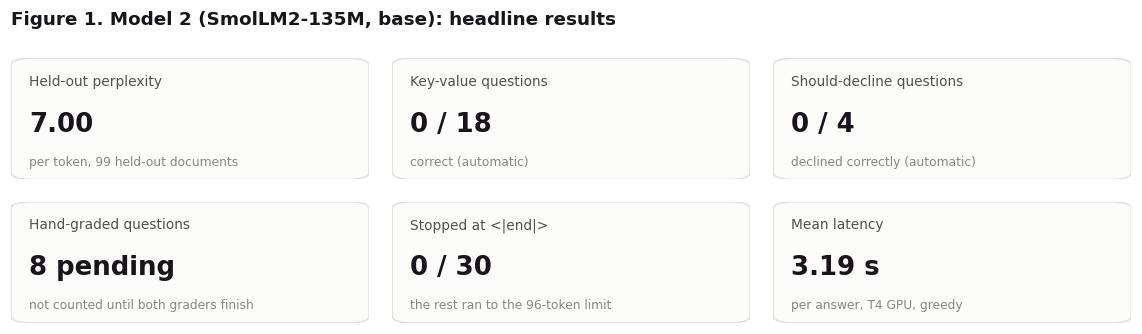

Saved: /content/drive/MyDrive/nutrition-assistant/results/base/smollm2-135m/base_smollm2-135m_20261113-1325/figures and /content/drive/MyDrive/nutrition-assistant/repo_exports/smollm2-135m/results/figures


In [17]:
import importlib, plots
importlib.reload(plots)
import matplotlib.pyplot as plt
from IPython.display import display
if "RESULTS" not in globals() or not os.path.exists(f"{RESULTS}/answers.csv"):
    raise RuntimeError("Results of this run are not in memory: use Runtime -> Run all (Steps 0-12 first).")
FIGS = f"{RESULTS}/figures"; os.makedirs(FIGS, exist_ok=True)
plots.style()
answers, saved_metrics = plots.load_run(RESULTS)

print("Test set: question type x difficulty")
display(plots.composition_table(answers))
plots.fig_headline(answers, saved_metrics, "Model 2 (SmolLM2-135M, base)", f"{FIGS}/fig1_headline.png", 1)
plt.show()
if not SMOKE:
    EXP_FIGS = f"{EXPORTS}/results/figures"; os.makedirs(EXP_FIGS, exist_ok=True)
    for f in sorted(os.listdir(FIGS)):
        shutil.copy(f"{FIGS}/{f}", f"{EXP_FIGS}/base_{f}")
    print("Saved:", FIGS, "and", EXP_FIGS)


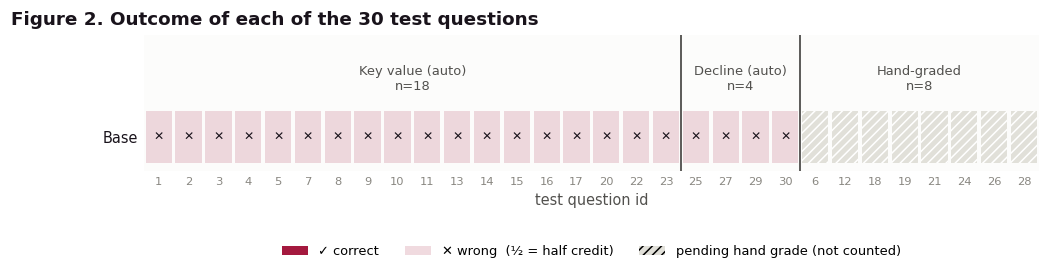

In [18]:
plots.fig_outcomes([("Base", answers)], f"{FIGS}/fig2_outcomes.png", 2)
plt.show()

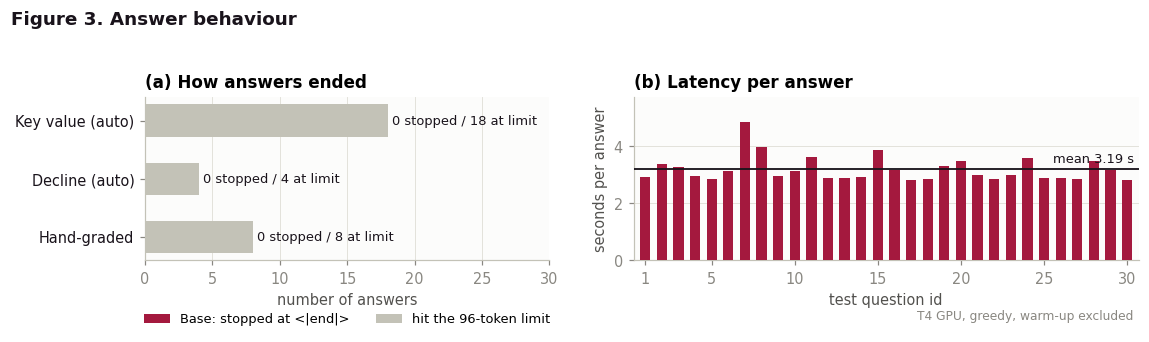

In [19]:
plots.fig_behaviour([("Base", answers)], f"{FIGS}/fig3_behaviour.png", 3)
plt.show()

## Step 14. GPT-2 small vs SmolLM2-135M (both base, same test)
Reads the GPT-2 Notebook 1 results and the GPT-2 tokenizer from this Drive **without changing them**. Colour = stage (both are Base); the model is shown by the fill (GPT-2 solid, SmolLM2 hatched) or the line (GPT-2 solid, SmolLM2 dashed), and every bar is labelled.

- **Figure 4** the held-out text: word-level perplexity (comparable across the two tokenizers; the per-token values are shown in brackets but are *not* comparable) and how many tokens each tokenizer needs for the same text.
- **Figure 5** the outcome of every test question for both models.
- **Figure 6** how answers ended, and latency per answer (with each model's depth and width from its config).
- **Table** how the two tokenizers split typical nutrition phrases.

GPT-2 results (read-only): /content/drive/MyDrive/nutrition-assistant/results/base/gpt2-small/base_gpt2-small_20261113-1307


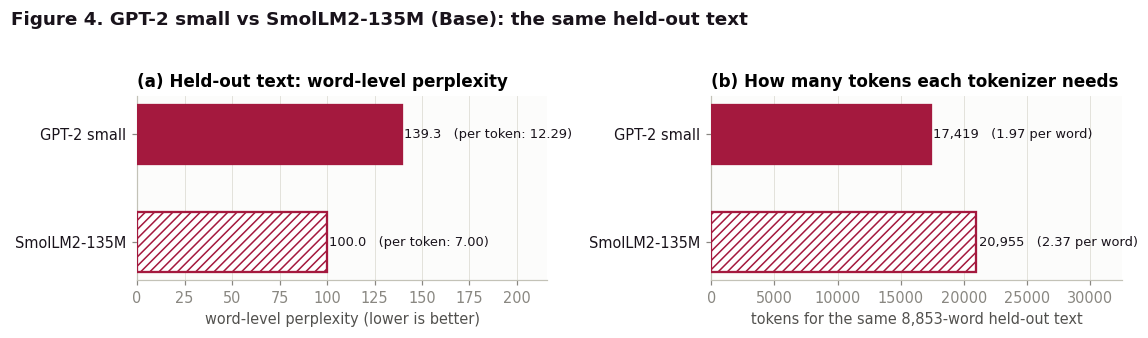

How the two tokenizers split typical phrases (pieces separated by |):


,text,GPT-2: tokens,GPT-2: pieces,SmolLM2: tokens,SmolLM2: pieces
0,"Per 100 g: 165 kcal, 31.0 g protein",12,"Per| 100| g|:| 165| kcal|,| 31|.|0| g| protein",21,"Per| |1|0|0| g|:| |1|6|5| k|cal|,| |3|1|.|0| g..."
1,How much sodium is in 1 cup of whole milk?,11,How| much| sodium| is| in| 1| cup| of| whole| ...,12,How| much| sodium| is| in| |1| cup| of| whole|...
2,0.53 g of salt per 96 g serving,10,0|.|53| g| of| salt| per| 96| g| serving,13,0|.|5|3| g| of| salt| per| |9|6| g| serving


Saved: /content/drive/MyDrive/nutrition-assistant/comparison/figures


In [20]:
import glob
from transformers import AutoTokenizer, AutoConfig
if SMOKE:
    raise RuntimeError("Smoke run: the comparison uses only full runs (set RUN_MODE = 'full').")
G_RUNS = sorted(glob.glob(f"{ROOT}/results/base/gpt2-small/base_gpt2-small_*/answers.csv"))
G_CKPT = f"{ROOT}/checkpoints/gpt2-small/base_project"
if not G_RUNS or not os.path.isdir(G_CKPT):
    raise RuntimeError(f"GPT-2 Notebook 1 results or checkpoint not found under {ROOT} (run the GPT-2 Notebook 1 with this Drive first).")
G_RESULTS = os.path.dirname(G_RUNS[-1])
g_answers, g_metrics = plots.load_run(G_RESULTS)
if list(g_answers.id) != list(answers.id) or g_metrics.get("n_questions") != len(answers):
    raise RuntimeError("The GPT-2 and SmolLM2 runs were not scored on the same questions.")
g_tok = AutoTokenizer.from_pretrained(G_CKPT)                        # read-only
g_cfg = AutoConfig.from_pretrained(G_CKPT)
g_wppl, g_scored = word_perplexity(g_tok, g_metrics["heldout_perplexity"])
print("GPT-2 results (read-only):", G_RESULTS)

CMP = f"{ROOT}/comparison/figures"; os.makedirs(CMP, exist_ok=True)
rows = [{"model": "GPT-2 small", "word_ppl": g_wppl, "token_ppl": g_metrics["heldout_perplexity"], "tokens": g_scored, "words": n_words},
        {"model": "SmolLM2-135M", "word_ppl": wppl_project, "token_ppl": ppl_project, "tokens": n_scored, "words": n_words}]
info = {"GPT-2 small": f"{g_cfg.n_layer} layers x {g_cfg.n_embd}",
        "SmolLM2-135M": f"{model.config.num_hidden_layers} layers x {model.config.hidden_size}"}
plots.fig_family_heldout(rows, f"{CMP}/base_fig4_heldout_gpt2_vs_smollm2.png", 4)

plt.show()

print("How the two tokenizers split typical phrases (pieces separated by |):")
split = plots.token_split_table({"GPT-2": g_tok, "SmolLM2": tok},
                                ["Per 100 g: 165 kcal, 31.0 g protein", "How much sodium is in 1 cup of whole milk?",
                                 "0.53 g of salt per 96 g serving"])
display(split)
split.to_csv(f"{CMP}/base_token_split_examples.csv", index=False)
print("Saved:", CMP)


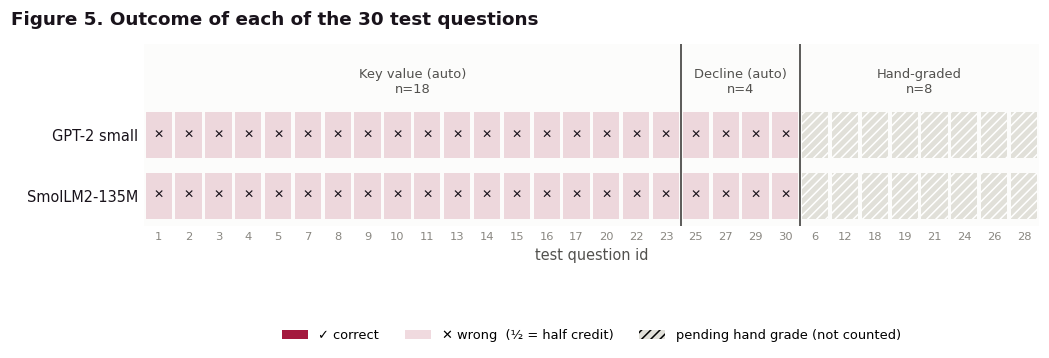

In [21]:
plots.fig_outcomes([("GPT-2 small", g_answers), ("SmolLM2-135M", answers)], f"{CMP}/base_fig5_outcomes_gpt2_vs_smollm2.png", 5)
plt.show()

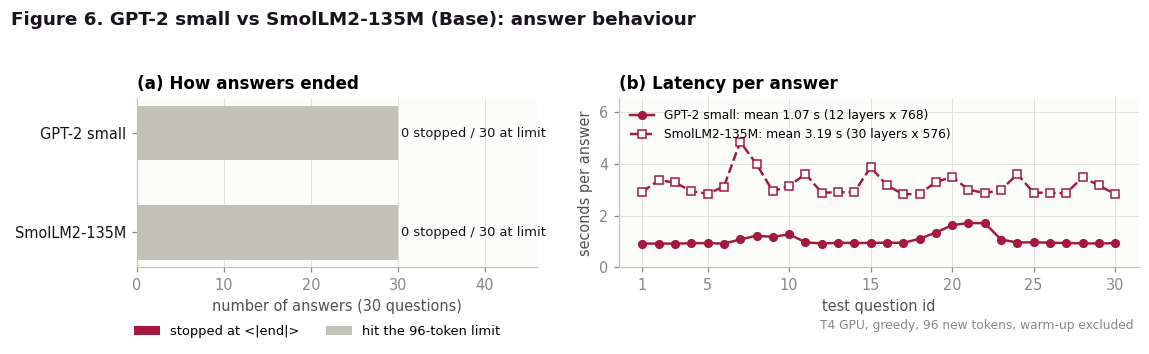

In [22]:
plots.fig_family_behaviour([("GPT-2 small", g_answers), ("SmolLM2-135M", answers)], info, f"{CMP}/base_fig6_behaviour_gpt2_vs_smollm2.png", 6)
plt.show()

## Step 15. Error analysis
Every answer below full score (and every hand-graded answer still pending) gets **one suggested primary cause** from the five categories of the brief. The rules are written in `error_analysis.py` and are deliberately simple:

| Category | Suggested when |
|---|---|
| Refusal error | a should-decline question was answered (or a normal question was declined) |
| Format failure | no answer at all: the model only repeats the question, writes new questions, or runs to the token limit without a single statement |
| Hallucination | it makes statements with numbers that are not in the question, but not the expected value |
| Knowledge missing | it makes statements, but without the needed value |
| Test-case problem | never suggested automatically: set by the team if a test question or its key turns out to be wrong |

The table is saved as `error_analysis.csv`; the team confirms or changes each row in `final_category` (re-running this step keeps those edits). Hand-graded answers still pending are included and marked `pending`; they are **not** counted as wrong in any score.

In [23]:
%%writefile error_analysis.py
"""Rule-based error analysis shared by the notebooks (Base, CPT, SFT; GPT-2 and SmolLM2).

Every answer that did not get full marks (and every hand-graded answer still pending) gets ONE suggested primary
cause from the course's five categories. The rules are simple and written down here, so they can be checked;
the team confirms or changes each one in the `final_category` column (test_case_problem is only set by the team).

  refusal_error      should-decline question answered, or a question it should answer declined
  format_failure     no answer: the model only repeats the question / writes new questions / runs to the token limit
                     without a single statement
  hallucination      it states numbers that are not in the question, but they are not the expected value
  knowledge_missing  it writes statements, but without the needed value
"""
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CATEGORIES = ["format_failure", "hallucination", "knowledge_missing", "refusal_error", "test_case_problem"]
LABEL = {"format_failure": "Format failure", "hallucination": "Hallucination", "knowledge_missing": "Knowledge missing",
         "refusal_error": "Refusal error", "test_case_problem": "Test-case problem"}
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^\w\s.]", " ", str(s).lower())).strip()
NUM = re.compile(r"\d+(?:\.\d+)?")


def features(question, answer, cfg):
    q, a = norm(question), norm(answer)
    head = q[:30]
    sentences = [s.strip() for s in re.split(r"(?<=[.?!])\s+|\n+", str(answer)) if s.strip()]
    asked = [norm(s) for s in sentences if s.endswith("?")]      # questions the model wrote (copies or new ones)
    is_copy = lambda s: norm(s) in q or head in norm(s) or any(norm(s) in x for x in asked)  # incl. cut-off pieces
    QWORDS = ("what", "how", "which", "does", "do", "is", "are", "can", "should", "why", "when", "where", "who")
    cut_question = lambda s: s is sentences[-1] and s[-1:] not in ".!:" and norm(s).split()[0] in QWORDS  # cut at the limit
    statements = [s for s in sentences if not s.endswith("?") and not is_copy(s) and not cut_question(s) and len(s.split()) >= 4]
    from scoring import declined
    return {
        "starts_with_question": a.startswith(head),
        "question_copies": a.count(head),
        "statements": len(statements),
        "new_numbers": len(set(NUM.findall(norm(" ".join(statements)))) - set(NUM.findall(q))),
        "declined": declined(answer, cfg),
    }


def suggest(row, f):
    if row["scoring"] == "decline" or f["declined"]:
        return "refusal_error"
    if f["statements"] == 0:
        return "format_failure"
    return "hallucination" if f["new_numbers"] else "knowledge_missing"


def analyse(answers, cfg, keep_path=None):
    """Table of every answer below full score (pending hand grades included, marked), with features and a suggestion.
    If keep_path exists, the team's final_category / notes are kept."""
    rows = []
    for r in answers.to_dict("records"):
        pending = pd.isna(r["final_score"])
        if not pending and r["final_score"] >= 1:
            continue
        f = features(r["question"], r["model_answer"], cfg)
        rows.append({"id": r["id"], "scoring": r["scoring"], "difficulty": r["difficulty"],
                     "grade": "pending" if pending else r["final_score"], "stopped_at_end": r["stopped_at_stop_token"],
                     **f, "suggested_category": suggest(r, f), "final_category": "", "notes": "",
                     "question": r["question"], "expected_answer": r["expected_answer"], "model_answer": r["model_answer"]})
    ea = pd.DataFrame(rows)
    if keep_path and os.path.exists(keep_path) and len(ea):
        old = pd.read_csv(keep_path, dtype=str).fillna("").set_index("id")
        for c in ["final_category", "notes"]:
            ea[c] = ea.id.astype(str).map(old[c]).fillna("")
    return ea


def summary_table(named):
    """named: [(model name, error table)] -> counts per suggested category."""
    t = pd.DataFrame({n: ea.suggested_category.value_counts() for n, ea in named}).reindex(CATEGORIES).fillna(0).astype(int)
    t.index = [LABEL[c] for c in t.index]
    t.loc["total below full score"] = t.sum()
    return t


def fig_categories(named, colors, hatches, path, number, title_suffix=""):
    """Horizontal bars: suggested primary cause per category, one bar per model (colour = stage, fill = model)."""
    from plots import INK, _title
    fig, ax = plt.subplots(figsize=(10.5, 3.3))
    h = .7 / len(named)
    for k, (name, ea) in enumerate(named):
        counts = ea.suggested_category.value_counts()
        for i, c in enumerate(CATEGORIES):
            y = (len(CATEGORIES) - 1 - i) + (len(named) - 1) / 2 * h - k * h
            v = int(counts.get(c, 0))
            ax.barh(y, max(v, .15), height=h * .88, color=colors[name] if hatches[name] is None else "white",
                    edgecolor=colors[name], hatch=hatches[name], lw=1.4, zorder=3)
            ax.text(max(v, .15) + .3, y, f"{v}" + ("" if len(named) == 1 else f"  {name}"), va="center", color=INK, fontsize=8.5)
    ax.set_yticks(range(len(CATEGORIES))[::-1]); ax.set_yticklabels([LABEL[c] for c in CATEGORIES], color=INK)
    ax.set_xlim(0, 34); ax.set_xlabel("answers below full score (of 30; hand-graded ones still pending are included)")
    ax.grid(axis="y", visible=False)
    if len(named) > 1:
        ax.legend(handles=[Patch(fc=colors[n] if hatches[n] is None else "white", ec=colors[n], hatch=hatches[n], label=n)
                           for n, _ in named], loc="lower right", fontsize=8.5)
    ax.text(1, -.3, "Suggested primary cause (rule-based); the team confirms each one. Test-case problems are set by hand only.",
            transform=ax.transAxes, ha="right", color="#898781", fontsize=8)
    _title(fig, f"Figure {number}. Error analysis: suggested primary cause{title_suffix}", y=1.02)
    fig.tight_layout(); fig.savefig(path); return fig


def examples(ea, per_category=1, width=220):
    """One short real example per suggested category."""
    out = []
    for c in CATEGORIES:
        d = ea[ea.suggested_category == c]
        for r in d.head(per_category).itertuples():
            a = re.sub(r"\s+", " ", str(r.model_answer))
            out.append(f"- **{LABEL[c]}** (Q{r.id}, {r.scoring}): *{r.question}*  \n  expected: {r.expected_answer}  \n"
                       f"  model: \"{a[:width]}{'…' if len(a) > width else ''}\"")
    return "\n".join(out)


Writing error_analysis.py


Suggested primary cause of every answer below full score:


,GPT-2 small,SmolLM2-135M
Format failure,26,17
Hallucination,0,1
Knowledge missing,0,8
Refusal error,4,4
Test-case problem,0,0
total below full score,30,30


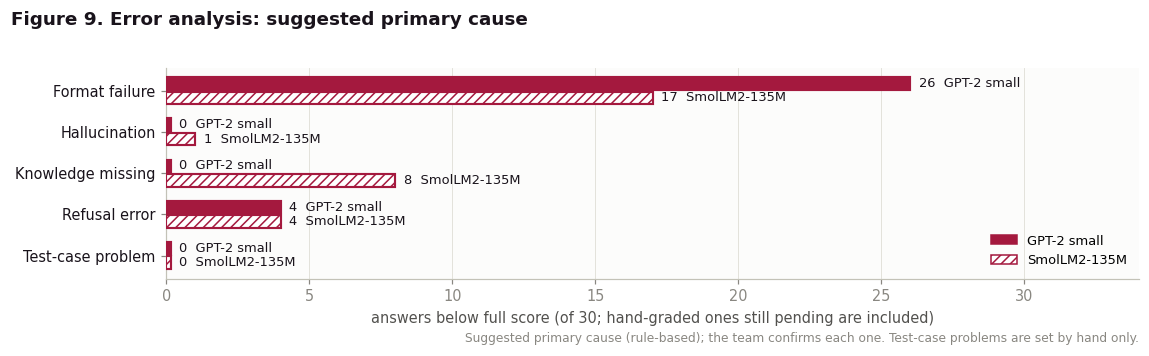

What the answers look like (SmolLM2-135M):


,scoring,grade,starts_with_question,question_copies,statements,new_numbers,stopped_at_end,suggested_category
id,,,,,,,,
1,key_match,0.0,True,6,0,0,False,format_failure
2,key_match,0.0,True,5,1,0,False,knowledge_missing
3,key_match,0.0,True,6,0,0,False,format_failure
4,key_match,0.0,True,6,0,0,False,format_failure
5,key_match,0.0,True,6,0,0,False,format_failure
7,key_match,0.0,True,5,0,0,False,format_failure
8,key_match,0.0,True,2,3,0,False,knowledge_missing
9,key_match,0.0,True,5,0,0,False,format_failure
10,key_match,0.0,True,6,0,0,False,format_failure


**One real example per category (SmolLM2-135M)**

- **Format failure** (Q1, key_match): *How much protein is in 100 g of whole milk?*  
  expected: 3.15 g of protein per 100 g of whole milk (3.25% fat).  
  model: "How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? How much protein is in 100 g of whole milk? …"
- **Hallucination** (Q18, manual): *Which has more protein per 100 g: cooked lentils or cooked chickpeas?*  
  expected: Cooked lentils, slightly: 9.02 g per 100 g versus 8.86 g for cooked chickpeas.  
  model: "Which has more protein per 100 g: cooked lentils or cooked chickpeas? The protein content of lentils and chickpeas is 11.5 g per 100 g. The protein content of chickpeas is 12.5 g per 100 g. The protein content of lentils…"
- **Knowledge missing** (Q2, key_match): *How many calories are in 100 g of banana?*  
  expected: 89 kcal per 100 g of raw banana.  
  model: "How many calories are in 100 g of banana? ## How many calories are in 100 g of banana? How many calories are in 100 g of banana? 100 g of banana contains 100 calories. ## How many calories are in 100 g of banana? How man…"
- **Refusal error** (Q25, decline): *How much sugar is in 100 g of cooked shrimp?*  
  expected: I don't know: the sugar value for cooked shrimp is not reported in the database, so the assistant says the information is not available instead of estimating.  
  model: "How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shrimp? How much sugar is in 100 g of cooked shr…"

Saved: /content/drive/MyDrive/nutrition-assistant/results/base/smollm2-135m/base_smollm2-135m_20261113-1325/error_analysis.csv and the comparison figure in comparison/figures


In [27]:
import importlib, error_analysis as E
importlib.reload(E)
from IPython.display import display, Markdown
EA_PATH = f"{RESULTS}/error_analysis.csv"
ea = E.analyse(answers, cfg, keep_path=EA_PATH)
ea.to_csv(EA_PATH, index=False)
g_ea = E.analyse(g_answers, cfg)                                  # GPT-2 answers, read-only (saved in comparison/)
g_ea.to_csv(f"{ROOT}/comparison/base_error_analysis_gpt2-small.csv", index=False)
NAMED = [("GPT-2 small", g_ea), ("SmolLM2-135M", ea)]
HATCH = {"GPT-2 small": None, "SmolLM2-135M": "////"}
FIGS_EA = CMP
print("Suggested primary cause of every answer below full score:")
display(E.summary_table(NAMED))
E.fig_categories(NAMED, {n: plots.MODEL_COLORS["Base"] for n, _ in NAMED}, HATCH, f"{FIGS_EA}/fig7_error_categories.png", 9)
plt.show()
print("What the answers look like (SmolLM2-135M):")
display(ea[["id", "scoring", "grade", "starts_with_question", "question_copies", "statements", "new_numbers",
            "stopped_at_end", "suggested_category"]].set_index("id"))
display(Markdown("**One real example per category (SmolLM2-135M)**\n\n" + E.examples(ea)))
print("Saved:", EA_PATH, "and the comparison figure in comparison/figures")


## Step 16. Reflection
The facts first (computed from the saved files, both models), then the reflection written from them.

In [25]:
# The numbers behind the reflection, computed from the saved results (so the text below can be checked)
def facts(name, a, e, m):
    n = len(a)
    stopped = int(a.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
    f = e.set_index("id")
    return {"model": name, "answers": n, "correct (auto)": f"{int((a[a.scoring != 'manual'].final_score >= 1).sum())} / {int((a.scoring != 'manual').sum())}",
            "declined correctly": f"{int((a[a.scoring == 'decline'].final_score >= 1).sum())} / {int((a.scoring == 'decline').sum())}",
            "stopped at <|end|>": f"{stopped} / {n}", "start by repeating the question": f"{int(f.starts_with_question.sum())} / {len(f)}",
            "mean copies of the question": round(float(f.question_copies.mean()), 1),
            "contain at least one statement": f"{int((f.statements > 0).sum())} / {len(f)}",
            "state new numbers": f"{int((f.new_numbers > 0).sum())} / {len(f)}",
            "held-out perplexity (own tokens)": m["heldout_perplexity"], "mean latency (s)": m["mean_latency_s"]}
FACTS = pd.DataFrame([facts(*x) for x in [("GPT-2 small", g_answers, g_ea, g_metrics), ("SmolLM2-135M", answers, ea, saved_metrics)]]).set_index("model").T
display(FACTS)


model,GPT-2 small,SmolLM2-135M
answers,30,30
correct (auto),0 / 22,0 / 22
declined correctly,0 / 4,0 / 4
stopped at <|end|>,0 / 30,0 / 30
start by repeating the question,30 / 30,29 / 30
mean copies of the question,6.9,3.8
contain at least one statement,0 / 30,11 / 30
state new numbers,0 / 30,1 / 30
held-out perplexity (own tokens),12.294,6.998
mean latency (s),1.069,3.187


In [26]:
# comparison sentences generated from the numbers above, so they always match the data
gw, sw = rows[0]["word_ppl"], rows[1]["word_ppl"]
gst, sst = int((g_ea.statements > 0).sum()), int((ea.statements > 0).sum())
display(Markdown(f"""**In numbers.** On the same held-out text SmolLM2-135M has a word-level perplexity of **{sw:.1f}** against **{gw:.1f}** for GPT-2 small
({100 * (1 - sw / gw):.0f}% lower), so it predicts our nutrition text better before any training. It needs {rows[1]['tokens']:,} tokens for that text against
{rows[0]['tokens']:,} for GPT-2, mainly because it writes numbers digit by digit. In the test, {sst} of its {len(ea)} answers below full score contain at least one
statement, against {gst} of {len(g_ea)} for GPT-2. Its mean latency is {saved_metrics['mean_latency_s']:.2f} s against {g_metrics['mean_latency_s']:.2f} s
({info['SmolLM2-135M']} against {info['GPT-2 small']})."""))


**In numbers.** On the same held-out text SmolLM2-135M has a word-level perplexity of **100.0** against **139.3** for GPT-2 small
(28% lower), so it predicts our nutrition text better before any training. It needs 20,955 tokens for that text against
17,419 for GPT-2, mainly because it writes numbers digit by digit. In the test, 11 of its 30 answers below full score contain at least one
statement, against 0 of 30 for GPT-2. Its mean latency is 3.19 s against 1.07 s
(30 layers x 576 against 12 layers x 768).

### Reflection: SmolLM2-135M (base) and the comparison with GPT-2 small

**What the base model does.** Like GPT-2, SmolLM2-135M base is a text-continuation model: it has not been instruction-tuned, has never seen our template, and the three chat tokens were added in Step 7 with untrained embeddings. It also **runs to the 96-token limit on every question** and **never stops at `<|end|>`**, and most of its answers start by repeating the question. Some of its answers continue with a sentence about the topic or write a new, related question instead of repeating ours (the "statements" column and the examples above show which; the paragraph "In numbers" gives the counts for both models). Those sentences are fluent but give no correct value, so they count as hallucinations or missing knowledge rather than right answers.

**Why it still scores zero.** Better language modelling (lower perplexity) is not the same as answering: without SFT the model does not know that a question should be followed by a short answer with the exact value, and it has no notion of declining out-of-scope or medical questions (0 of 4 declined). Exact nutrition values for specific foods and products are also not something a 135M-parameter base model reliably memorises.

**What the comparison shows (both base).**
- **Held-out text:** SmolLM2 is the stronger language model for our domain (lower word-level perplexity). The per-token perplexities (12.29 vs 7.00) look even more different, but they are not comparable because the two tokenizers split the text differently.
- **Answers:** both models get 0 auto-scored questions right and decline none, so at this stage the test cannot separate them; the difference is in *how* they fail (see the error-category figure).
- **Cost:** SmolLM2 is about three times slower per answer on the T4, because it has 30 layers against GPT-2's 12 (similar parameter count, deeper and narrower network).
- **Tokenizer:** SmolLM2 splits numbers into single digits ("165" -> "1", "6", "5"). This uses more tokens, but it may help it learn and copy exact values after CPT and SFT: one of the things the next stages will show.

**What the next stages should change.** As for GPT-2: CPT should lower held-out perplexity; SFT should create the answer format, stopping at `<|end|>` and refusals; RAG should supply exact values. Because SmolLM2 starts from a lower perplexity, the interesting question is whether it also ends with higher accuracy after SFT, and whether that gain is worth the extra latency.

**Limits.** The categories are rule-based suggestions that the team must confirm; 8 hand grades are pending for each model; one question is 3.3 percentage points, so small differences are not meaningful.